# PROJEKT 1 - model scoringowy/ratingowy
### Część I: walidacja i podziały · jakość danych · EDA · przygotowanie cech

**Dane:** `zbiór_5.csv` (3000 spółek z o.o., 222 cechy) · **Target:** `default` · **Docelowa tendencja centralna PD:** 4%

Ta część realizuje punkty **3.1 Walidacja i podziały** oraz **3.2 Przygotowanie i EDA**. Jej wynikiem są: zamrożony podział danych, schemat walidacji krzyżowej oraz dwa pipeline'y przygotowania cech — dla modelu interpretowalnego i dla modelu black-box. Korzystają z nich kolejne części projektu: modele, wyjaśnialność i kalibracja.

**Najważniejsze ustalenia**

1. **Plik jest posortowany według targetu** (178 defaultów to pierwsze 178 wierszy). Bez tasowania każdy podział byłby bezużyteczny, a numer wiersza byłby „idealną” cechą.
2. **O wszystkim decyduje liczba defaultów: 178** (107 w zbiorze treningowym). Stąd podział 60/20/20, 5 foldów, mała liczba koszyków i cech oraz szerokie przedziały ufności wyników.
3. **Zero nie zawsze znaczy zero.** U jednostek mikro (26% próby) ok. 60 cech to pozycje nieraportowane — w danych są tam zera. Dodatkowo wskaźnik z zerowym mianownikiem ma w danych wartość `licznik / 100`. Obie sytuacje traktujemy jako wartości specjalne (brak danych z własnym koszykiem), a nie jako liczby.
4. **Sygnał jest umiarkowany, monotoniczny i mocno zduplikowany:** najsilniejsze cechy mają Gini 0,3–0,4 poza próbą uczącą; 193 cechy liczbowe układają się w 90 klastrów korelacji.
5. **Przygotowanie cech poza walidacją krzyżową zawyża AUC o ok. 0,07**, a na danych bez żadnego sygnału „znajduje” AUC = 0,68. Dlatego binning, WoE i selekcja są krokami `Pipeline`.
6. **Kwestia otwarta:** dwie z najsilniejszych cech (`wsk_index_skr_zaw`, `wsk_index_nowe`) nie są opisane w słowniku i odpowiadają za ok. 0,06 AUC. Ich definicję trzeba potwierdzić przed budową modeli.

## ETAP 0. Konfiguracja i odtwarzalność

### 0.1. Wczytanie najpotrzebniejszych pakietów i kontrola ich wersji

In [1]:
import hashlib
import re
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyArrowPatch, Rectangle
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import chi2_contingency, mannwhitneyu, norm
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedGroupKFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline

print("Python:", sys.version.split()[0], "| numpy:", np.__version__, "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__, "| scipy:", scipy.__version__, "| matplotlib:", matplotlib.__version__)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

Python: 3.14.0 | numpy: 2.3.4 | pandas: 2.3.3 | scikit-learn: 1.7.2 | scipy: 1.16.3 | matplotlib: 3.10.7


### 0.2. Parametry projektu i styl wykresów

In [29]:
# --- parametry projektu --- #
RNG_SEED = 42                          # jedno ziarno dla całego projektu
PLIK_DANYCH = "zbiór_5.csv"
TARGET = "default"
PD_DOCELOWE = 0.04                     # tendencja centralna PD (wykorzystana na etapie kalibracji)
TEST_SIZE, VALID_SIZE = 0.20, 0.20     # udziały w całym zbiorze; TRAIN = 60%
N_SPLITS, N_REPEATS = 5, 5             # Stratified K-fold oraz liczba powtórzeń w wariancie powtarzanym

# --- kolory: stała paleta sprawdzona pod kątem rozróżnialności (także przy zaburzeniach widzenia barw) ---
KOL = {"train": "#2a78d6", "valid": "#eb6834", "test": "#1baf7a", "logit": "#6250d6", "black-box": "#eda100"}

## ETAP 1. Dane wejściowe i kontrola strukturalna

W tym etapie oglądamy plik „taki, jaki przyszedł”: wymiary, typy, słownik zmiennych, zmienną objaśnianą, kolejność rekordów i jednostkę obserwacji. Są to wyłącznie kontrole **strukturalne** — niczego nie dopasowujemy do danych i (poza samym rozkładem targetu, potrzebnym do stratyfikacji) nie badamy zależności cech z targetem. Wszystko, co wymaga „uczenia się” z danych, zaczyna się dopiero po podziale (ETAP 2) i jest liczone wyłącznie na zbiorze treningowym. Dodatkowo przeprowadzane są tutaj szczegółowe rozważania i decyzje odnośnie zmiennych, które okazały się problematyczne.

### 1.1. Wczytanie i wstępna weryfikacja danych wejściowych

In [3]:
kandydaci = [Path(PLIK_DANYCH), *sorted(Path(".").glob("zbi*r_5.csv"))]
sciezka = next((p for p in kandydaci if p.exists()), None)
assert sciezka is not None, f"Nie znaleziono pliku {PLIK_DANYCH} w katalogu {Path.cwd()}"

df_local = pd.read_csv(sciezka)
print("Plik:", sciezka.name, "| wymiar danych wejściowych:", df_local.shape)
print("Typy kolumn:", df_local.dtypes.astype(str).value_counts().to_dict())

print("\n---Dane wejściowe (7 obserwacji)---")
display(df_local.head(7))

Plik: zbiór_5.csv | wymiar danych wejściowych: (3000, 223)
Typy kolumn: {'float64': 216, 'int64': 5, 'object': 2}

---Dane wejściowe (7 obserwacji)---


,szczegolnaFormaPrawna_Symbol,formaWlasnosci_Symbol,pkdKod,wsk_index_aktywne,wsk_index_skr_zaw,wsk_index_nowe,wsk_liczba_dni_istnienia,Aktywa,Aktywa_trwale,Wartosci_niematerialne_prawne,Wartosc_firmy,Rzeczowe_aktywa_trwale,Srodki_trwale,Naleznosci_dlugoterminowe,Inwestycje_dlugoterminowe,Rozliczenia_miedzyokresowe_dlugie,Aktywa_obrotowe,Zapasy,Naleznosci_krotkoterminowe,Naleznosci_dostaw_uslug_12m_powiazane,...,wsk_obrotowosc_gotowkowa,wsk_struktura_majatku,wsk_struktury_kapitalu,wsk_zast_kapitalu_wlasnego,wsk_zast_kapitalu_podstawowego,wsk_zast_kapitalu_stalego,wsk_zast_kapitalu_obcego,wsk_sytuacji_fin,wsk_struktura_kap_wlasnego_1,wsk_struktura_kap_wlasnego_2,wsk_struktura_kap_wlasnego_s_1,wsk_struktura_kap_wlasnego_s_2,wsk_zadluzenia,wsk_zob_dlugoterminowe_aktywa_rzeczowe,wsk_zob_oprocentowanych,wsk_zob_oprocentowanych_aktywa_rzeczowe,wsk_struktura_kap_obcego_s,wsk_zob_s_aktywa_rzeczowe,wsk_fin_majatku_kapitalem,default
0,117,214,2229,-0.002200,0.313079,0.302703,2321,142410.72,103108.88,0.0,0.0,52566.70,52566.70,0.00,50542.18,0.0,39301.84,0.00,29040.50,0.0,...,35.394587,2.623513,0.179144,0.209837,0.872864,0.609092,3.073003,0.068284,0.151927,0.151927,0.151927,0.163724,5.582103,0.289071,0.289071,0.289071,0.848073,0.776018,-2.073003,1
1,117,214,2849,-0.006410,0.259259,0.193548,2066,5000.00,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.0,5000.00,0.00,0.00,0.0,...,0.000000,0.000000,50.000000,50.000000,50.000000,50.000000,0.000000,0.500000,1.000000,1.000000,1.000000,inf,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000,1.000000,1
2,117,214,4120,0.022651,0.275066,0.262392,3166,13126.26,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.0,12126.26,0.00,12121.83,0.0,...,0.000000,0.000000,131.262600,131.262600,50.000000,131.262600,0.000000,1.312626,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.082466,1
3,117,214,4690,-0.004587,0.115842,0.300723,1951,1219468.16,242162.89,0.0,0.0,238162.89,0.00,0.00,4000.00,0.0,977305.27,6358.58,811441.28,0.0,...,55.021145,0.247786,0.206186,0.860810,0.825890,1.345594,1.034489,0.832111,0.170940,0.170940,0.170940,0.173503,4.849997,0.096269,0.152900,0.152900,0.829060,0.814289,-0.034489,1
4,117,216,6201,0.117207,0.396781,0.284008,2755,274553.22,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.0,274553.22,0.00,146340.70,0.0,...,4.348336,0.000000,81.868981,2712.401200,50.000000,2712.401200,0.012067,0.818690,0.987933,0.987933,0.987933,1.853484,0.012215,0.000000,0.000000,0.000000,0.012067,-0.454919,0.987933,1
5,117,215,4120,0.045820,0.325122,0.423268,7089,11523535.71,433597.43,0.0,0.0,8207.95,8207.95,82389.48,150000.00,193000.0,11089938.28,150000.00,4199015.08,405590.0,...,4950.312093,0.039098,2.368915,18.687813,22.230298,20.076697,0.308437,60.588741,0.703169,0.703169,0.703169,0.703187,0.422134,0.052260,0.000000,0.000000,0.296831,-0.278963,0.691563,1
6,117,214,4321,0.086237,0.394045,0.539706,1759,434719.82,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.0,434719.82,0.00,426177.37,0.0,...,7541.807600,0.000000,1.742633,2762.152700,50.000000,4347.198200,0.364613,0.017426,0.635387,0.635387,0.635387,0.635387,0.573844,0.364613,0.000000,0.000000,0.364613,0.364613,0.635387,1


### 1.2. Słownik i taksonomia zmiennych

In [12]:
NUM_COLS = df_local.select_dtypes(include="number").columns.tolist()
CAT_COLS = df_local.select_dtypes(exclude="number").columns.tolist()
print("df_local - cechy numeryczne:", len(NUM_COLS), "cech |", NUM_COLS)
print("df_local - cechy kategoryczne:", len(CAT_COLS), "cechy |", CAT_COLS)

df_local - cechy numeryczne: 221 cech | ['szczegolnaFormaPrawna_Symbol', 'formaWlasnosci_Symbol', 'pkdKod', 'wsk_index_aktywne', 'wsk_index_skr_zaw', 'wsk_index_nowe', 'wsk_liczba_dni_istnienia', 'Aktywa', 'Aktywa_trwale', 'Wartosci_niematerialne_prawne', 'Wartosc_firmy', 'Rzeczowe_aktywa_trwale', 'Srodki_trwale', 'Naleznosci_dlugoterminowe', 'Inwestycje_dlugoterminowe', 'Rozliczenia_miedzyokresowe_dlugie', 'Aktywa_obrotowe', 'Zapasy', 'Naleznosci_krotkoterminowe', 'Naleznosci_dostaw_uslug_12m_powiazane', 'Naleznosci_dostaw_uslug_pow12m_powiazane', 'Naleznosci_dostaw_uslug_12m_kapitale', 'Naleznosci_dostaw_uslug_pow12m_kapitale', 'Naleznosci_dostaw_uslug_12m_pozostale', 'Naleznosci_dostaw_uslug_pow12m_pozostale', 'Naleznosci_dostaw_uslug_pozostale_sadowe', 'Inwestycje_krotkoterminowe', 'Srodki_pieniezne', 'Rozliczenia_miedzyokresowe_krotkie', 'Kapital_wlasny', 'Kapital_podstawowy', 'Kapital_zapasowy', 'Zysk_netto', 'Zobowiazania_rezerwy', 'Rezerwy_na_zobowiazania', 'Rezerwa_z_tytulu_od

In [16]:
X_raw = df_local.drop(columns=TARGET)
y_raw = df_local[TARGET]

In [17]:
# --- PODZIAŁ ZMIENNYCH WEDŁUG ROLI ---

# KODY - zmienne, które są zapisane jako liczbowe, ale w rzeczywistości są kategoryczne (do zmiany)
KODY = ["szczegolnaFormaPrawna_Symbol", "formaWlasnosci_Symbol", "pkdKod"]
# SCHEMATY - zmienne kategoryczne
SCHEMATY = ["schemat_wsk_bilans", "schemat_wsk_rzis"]
# POZA_SLOWNIKIEM - zmienne, które nie zostały zawarte w Opisie Danych
POZA_SLOWNIKIEM = ["wsk_index_aktywne", "wsk_index_skr_zaw", "wsk_index_nowe", "schemat_wsk_bilans", "schemat_wsk_rzis"]
# WIEK - zmienna podejrzana
WIEK = ["wsk_liczba_dni_istnienia"]
# WSKAZNIKI - zmienne oznaczające wskazniki (zaczynające się od wsk_)
WSKAZNIKI = [c for c in X_raw.columns if c.startswith("wsk_")]

print("---Dokładny podział zmiennych po weryfikacji w danych bez TARGET---")
print("\nZmienne kategoryczne:", len(SCHEMATY), "cechy |", SCHEMATY)
print("Zmienne kodowe:", len(KODY), "cechy |", KODY)
print("Wskaźniki:", len(WSKAZNIKI), "cech |", WSKAZNIKI)
print("Pozycje kwotowe:", len(list(set(NUM_COLS)-set(WSKAZNIKI)-set(KODY))), "cech |", list(set(NUM_COLS)-set(WSKAZNIKI)-set(KODY)))
print("Zmienne nieopisane w słowniku:", len(POZA_SLOWNIKIEM), "cech |", POZA_SLOWNIKIEM)
print("Zmienna probelmatyczna:", WIEK)

display(pd.DataFrame({"zmienna kategoryczna": CAT_COLS, "liczba kategorii": X_raw[CAT_COLS].nunique(dropna=True).values,
    "wartości": [X_raw[c].dropna().unique().tolist() for c in CAT_COLS], "liczba braków": X_raw[CAT_COLS].isna().sum().values}))

---Dokładny podział zmiennych po weryfikacji w danych bez TARGET---

Zmienne kategoryczne: 2 cechy | ['schemat_wsk_bilans', 'schemat_wsk_rzis']
Zmienne kodowe: 3 cechy | ['szczegolnaFormaPrawna_Symbol', 'formaWlasnosci_Symbol', 'pkdKod']
Wskaźniki: 139 cech | ['wsk_index_aktywne', 'wsk_index_skr_zaw', 'wsk_index_nowe', 'wsk_liczba_dni_istnienia', 'wsk_kapital_do_aktywa', 'wsk_amortyzacja', 'wsk_koszty_operacyjne', 'wsk_Zobowiazania_krotkoterminowe', 'wsk_Zobowiazania_dlugoterminowe', 'wsk_marza_brutto_1', 'wsk_marza_brutto_2', 'wsk_stopa_marzy_brutto', 'wsk_rent_operacyjna', 'wsk_ROS', 'wsk_ROA', 'wsk_s_ROA', 'wsk_rent_operacyjna_aktywow', 'wsk_ROE', 'wsk_s_ROE', 'wsk_mnoznik_kap_wl', 'wsk_zwrot_aktywa_trwale', 'wsk_rent_kaptial_podstawowy', 'wsk_akt_generowania_got_1', 'wsk_akt_generowania_got_2', 'wsk_rent_sprzedazy', 'wsk_ebit', 'wsk_ebitda_1', 'wsk_ebitda_2', 'wsk_ebitda_3', 'wsk_marza_ebitda_1', 'wsk_marza_ebitda_2', 'wsk_marza_ebitda_3', 'wsk_marza_ebit', 'wsk_ebitda_aktywa_1', '

,zmienna kategoryczna,liczba kategorii,wartości,liczba braków
0,schemat_wsk_bilans,3,"[SFJIN, SFJMI, SFJMA]",0
1,schemat_wsk_rzis,3,"[SFJIN, SFJMI, SFJMA]",0


### 1.3. Kody

In [19]:
df_local["szczegolnaFormaPrawna_Symbol"].value_counts()

szczegolnaFormaPrawna_Symbol
117    3000
Name: count, dtype: int64

In [20]:
df_local["pkdKod"].value_counts()

pkdKod
6820    132
7022    105
4120    105
6201    101
4110     98
       ... 
4615      1
3230      1
4950      1
2433      1
9525      1
Name: count, Length: 378, dtype: int64

In [21]:
df_local["pkdKod"].unique()

array([2229, 2849, 4120, 4690, 6201, 4321, 5610, 9003, 8010, 6420, 6312,
       2120, 6492, 4941, 4611, 4642, 4671, 6622, 5210, 6810, 4110,  113,
       8621, 7490, 7112, 5629, 6910, 3832, 7810, 7022, 2932, 4621, 4791,
       3511, 4641, 4623, 4531, 5110, 6920, 6311, 1072, 4619,  161, 7320,
       7010, 7311, 8230, 7712, 5510, 5913, 3821, 7830, 8291, 4329, 8211,
       2720, 6820, 9101, 1729, 4332, 3320, 8622, 5813, 6619, 4312, 7732,
       4646, 6612, 8510, 8129, 1624, 3811, 4776, 3314, 4669, 6621, 4331,
       4339, 7111, 1052, 3109, 9601, 4311, 3514, 4799, 4920, 4939, 5911,
       2511, 4652, 1623, 4711, 6110, 7420, 2319, 7219, 8730, 4773, 7740,
       4677, 4742, 5320, 4741,  142, 2712, 5819, 6419,  111, 2562, 4618,
       4222, 4771, 8690, 4299, 6203, 3600, 4675, 3312, 8121, 7120, 4511,
       4673, 5229, 4931, 2825, 4724, 9511, 5829, 4774, 4645, 8110, 2363,
       4730, 8030, 4752, 7500, 2041, 2561, 4772, 4651, 4779, 1393, 4643,
       3311, 3700, 8553, 4612, 1392, 8559, 5221, 46

In [22]:
df_local["formaWlasnosci_Symbol"].value_counts()

formaWlasnosci_Symbol
214    2008
215     293
216     239
0       160
224      78
226      61
225      61
113      38
227      37
112       8
234       5
111       3
338       2
133       2
235       2
236       1
132       1
122       1
Name: count, dtype: int64

**Wnioski.**
* 222 cechy to: 5 kolumn kategorycznych (3 kody liczbowe + 2 schematy sprawozdań), 79 pozycji kwotowych, 139 wskaźników oraz zmienna potencjalnie problematyczna wiek firmy.
* `szczegolnaFormaPrawna_Symbol` ma jedną wartość (117) — cała próba to spółki z o.o., więc kolumna nie niesie informacji i zostanie usunięta.
* `pkdKod` wczytuje się jako liczba, przez co kody działów 01–09 tracą zero wiodące (np. `113` to w rzeczywistości `0113`. Branżę trzeba więc wyznaczać z kodu **uzupełnionego do 4 cyfr**; wycięcie dwóch pierwszych znaków z liczby przypisałoby te firmy do błędnych działów (np. `113` → dział 11).
* Schematy `SFJIN` / `SFJMA` / `SFJMI` najpewniej odpowiadają rodzajom e-sprawozdań — decydują o tym, które pozycje w ogóle są raportowane.

### 1.4. Weryfikacja zmiennej objaśnianej 'default'

In [24]:
print("Typ:", y_raw.dtype, "| liczba braków:", int(y_raw.isna().sum()),
      "| czy default przyjmuje wyłącznie 0 i 1:", bool(y_raw.dropna().isin([0, 1]).all()))
display(pd.DataFrame({"ilość": y_raw.value_counts(), "udział": y_raw.value_counts(normalize=True).round(4),
                      "procent": (y_raw.value_counts(normalize=True) * 100).round(2)}))

N_DEF, DR = int(y_raw.sum()), float(y_raw.mean())
print(f"Default rate (DR) w próbie: {DR:.2%}; docelowa tendencja centralna PD: {PD_DOCELOWE:.0%}")
print(f"Iloraz szans (docelowy / próba): {(PD_DOCELOWE / (1 - PD_DOCELOWE)) / (DR / (1 - DR)):.3f}"
      f"  ->  przesunięcie na skali logit: {np.log((PD_DOCELOWE / (1 - PD_DOCELOWE)) / (DR / (1 - DR))):+.3f}")

Typ: int64 | liczba braków: 0 | czy default przyjmuje wyłącznie 0 i 1: True


,ilość,udział,procent
default,,,
0,2822,0.9407,94.07
1,178,0.0593,5.93


Default rate (DR) w próbie: 5.93%; docelowa tendencja centralna PD: 4%
Iloraz szans (docelowy / próba): 0.661  ->  przesunięcie na skali logit: -0.415


Zmienna docelowa jest binarna i nie zawiera brakujących wartości. Udział obserwacji z defaultem wynosi **5,93%** (178 z 3000). **Nie obejmuje 4%** — próba jest więc „bardziej ryzykowna” niż docelowa tendencja centralna PD i sama częstość defaultów z próby nie może posłużyć za poziom PD. Na etapie kalibracji trzeba będzie przeskalować prawdopodobieństwa do 4% (rząd wielkości: przesunięcie o ok. −0,4 na skali logit).

Druga konsekwencja jest ważniejsza dla tej części projektu: **defaultów jest tylko 178**. To one, a nie 3000 obserwacji, wyznaczają „budżet informacji” — od nich zależy, jak dzielić dane.

### 1.5. Obserwacje danych

Łączna liczba braków w danych df_local: 20854

---Cechy zawierające jakiekolwiek braki---


,cecha,braki,procent braków,liczba unikalnych wartości
1,RP_przeplywy_operacyjne,2966,98.87,20
3,wsk_akt_generowania_got_2,2966,98.87,20
8,wsk_zysk_CF_operacyjny,2966,98.87,34
4,wsk_pokrycie_wyd_fin_gotowkowe_2,2966,98.87,20
5,wsk_pokrycie_zob_kr_gotowkowe_2,2966,98.87,20
6,wsk_zadluzenia_gotowki_2,2966,98.87,20
2,RP_amortyzacja,2873,95.77,99
7,wsk_plynnosc_biez_1,101,3.37,1997
0,wsk_kapital_do_aktywa,42,1.40,2647
9,wsk_struktura_kap_wlasnego_s_2,42,1.40,2689


Liczba obserwacji z co najmniej jednym brakiem: 2969


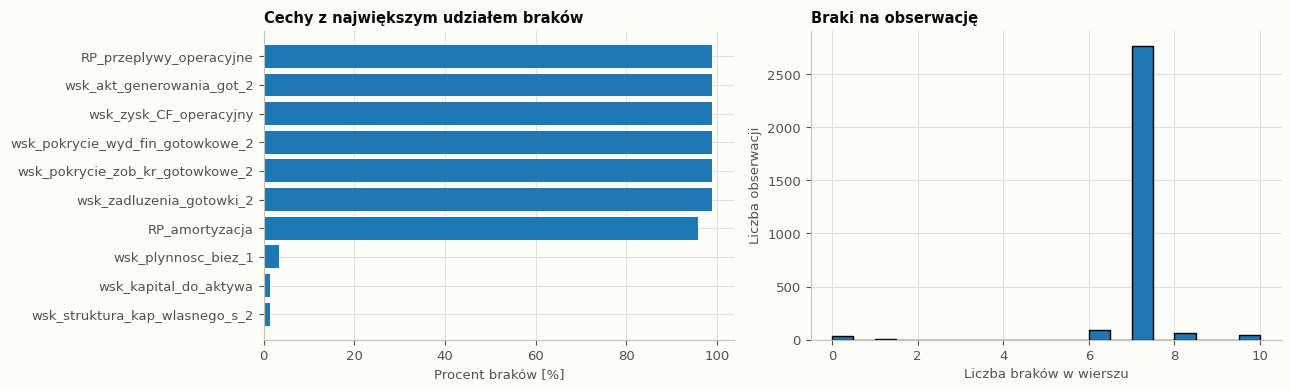

In [26]:
print("Łączna liczba braków w danych df_local:", df_local.isna().sum().sum())
braki = df_local.isna().sum(); braki = braki[braki > 0]
braki_df = pd.DataFrame({"cecha": braki.index, "braki": braki.values, "procent braków": braki.values / len(df_local) * 100,
    "liczba unikalnych wartości": df_local[braki.index].nunique(dropna=True).values}).sort_values("procent braków", ascending=False).round(2)
print("\n---Cechy zawierające jakiekolwiek braki---")
display(braki_df)

braki_w_wierszu = df_local.isna().sum(axis=1)
print("Liczba obserwacji z co najmniej jednym brakiem:", (braki_w_wierszu > 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
top = braki_df.query("braki > 0").head(20).iloc[::-1]
if len(top):
    axes[0].barh(top["cecha"], top["procent braków"])
axes[0].set_xlabel("Procent braków [%]")
axes[0].set_title("Cechy z największym udziałem braków")
axes[1].hist(braki_w_wierszu, bins=20, edgecolor="black")
axes[1].set_xlabel("Liczba braków w wierszu")
axes[1].set_ylabel("Liczba obserwacji")
axes[1].set_title("Braki na obserwację")
plt.tight_layout()
plt.show()

In [27]:
print("Liczba zduplikowanych obserwacji:", df_local.duplicated().sum())
print("Liczba zduplikowanych cech:", df_local.T.duplicated().sum())
duplikaty = df_local.columns[df_local.T.duplicated()].tolist()
print("Zduplikowane cechy:", duplikaty)
cechy_zduplikowane = []
for i, col in enumerate(df_local.columns):
    for prev_col in df_local.columns[:i]:
        if df_local[col].equals(df_local[prev_col]):
            cechy_zduplikowane.append(prev_col)
            break
display(pd.DataFrame({"cecha będąca duplikatem": duplikaty, "cechy właściwej": cechy_zduplikowane}))

Liczba zduplikowanych obserwacji: 0
Liczba zduplikowanych cech: 8
Zduplikowane cechy: ['wsk_rent_sprzedazy', 'wsk_zysk_operacyjny_zob_1', 'wsk_zadluzenie_gotowka', 'wsk_ebitda_zobowiazan_odsetki_1', 'wsk_ebitda_zobowiazan_odsetki_2', 'wsk_poziom_kosztow_operacyjnych', 'wsk_poziom_kosztow_finansowych', 'wsk_struktura_kap_wlasnego_1']


,cecha będąca duplikatem,cechy właściwej
0,wsk_rent_sprzedazy,wsk_ROS
1,wsk_zysk_operacyjny_zob_1,wsk_zysk_op_zobowiazania
2,wsk_zadluzenie_gotowka,wsk_koszty_odsetki_przychody
3,wsk_ebitda_zobowiazan_odsetki_1,wsk_ebitda_koszty_odsetkowe_1
4,wsk_ebitda_zobowiazan_odsetki_2,wsk_ebitda_koszty_odsetkowe_2
5,wsk_poziom_kosztow_operacyjnych,wsk_koszty_przychody
6,wsk_poziom_kosztow_finansowych,wsk_koszty_fin_przychody
7,wsk_struktura_kap_wlasnego_1,wsk_udzial_kap_wlasnego_aktywa_1


In [28]:
X_num = df_local.select_dtypes(include="number")
inf_counts = X_num.apply(lambda s: np.isposinf(s.to_numpy(dtype=float, na_value=np.nan)).sum())
minus_inf_counts = X_num.apply(lambda s: np.isneginf(s.to_numpy(dtype=float, na_value=np.nan)).sum())
print("Łączna liczba inf w danych:", inf_counts.sum())
print("Łączna liczba -inf w danych:", minus_inf_counts.sum())
inf_counts = inf_counts[inf_counts > 0]
display(inf_counts.sort_values(ascending=False).to_frame("liczba inf"))

X_num_finite = X_num.replace([np.inf, -np.inf], np.nan)

liczba_niebrakujacych = X_num_finite.notna().sum()
liczba_zer = (X_num_finite == 0).sum()
udzial_zer = liczba_zer.div(liczba_niebrakujacych.replace(0, np.nan))
duzo_zer = pd.DataFrame({"liczba obserwacji": liczba_niebrakujacych, "liczba zer": liczba_zer,
                         "udział zer": udzial_zer, "liczba unikalnych wartości": X_num_finite.nunique()})
duzo_zer = duzo_zer[duzo_zer["udział zer"] > 0.9]
print("\nLiczba cech z udziałem zer > 0.9:", len(duzo_zer))
display(duzo_zer.sort_values("udział zer", ascending=False).round(4))

Łączna liczba inf w danych: 1005
Łączna liczba -inf w danych: 0


,liczba inf
wsk_plynnosc_biez_1,901
wsk_struktura_kap_wlasnego_s_2,98
wsk_kapital_do_aktywa,6



Liczba cech z udziałem zer > 0.9: 34


,liczba obserwacji,liczba zer,udział zer,liczba unikalnych wartości
Zobowiazania_dostaw_uslug_pow12m_kapitale,3000,2999,0.9997,2
Naleznosci_dostaw_uslug_pow12m_kapitale,3000,2999,0.9997,2
Zobowiazania_dostaw_uslug_pow12m_powiazane,3000,2997,0.9990,4
Naleznosci_dostaw_uslug_pow12m_powiazane,3000,2995,0.9983,6
Ujemna_wartosc_firmy,3000,2994,0.9980,7
Pozostale_rezerwy,3000,2985,0.9950,16
Zobowiazania_dostaw_uslug_12m_kapitale,3000,2980,0.9933,21
Zobowiazania_dostaw_uslug_pow12m,3000,2974,0.9913,25
Wartosc_firmy,3000,2972,0.9907,29
Zobowiazania_dostaw_uslug_pow12m_pozostale,3000,2970,0.9900,31


## ETAP 2. Podział danych i schemat walidacji

Podział wykonujemy **przed** analizą jakości danych i EDA — tak, aby wszystko, co ma wpływ na budowę modeli (progi czyszczenia, binning, WoE, selekcja cech, hiperparametry), było wyznaczane wyłącznie na danych treningowych.

### 2.2. Podział stratyfikowany train / validation / test

In [33]:
TEST_SIZE  = 0.20    # 20% całości -> zbiór testowy (tylko ocena końcowa)
VALID_SIZE = 0.25    # 20% całości -> zbiór walidacyjny (kalibracja, early stopping, diagnostyka)

X_dev, X_test, y_dev, y_test = train_test_split(X_raw, y_raw, test_size=TEST_SIZE, stratify=y_raw, shuffle=True, random_state=RNG_SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_dev, y_dev, test_size=VALID_SIZE, stratify=y_dev, shuffle=True, random_state=RNG_SEED)

# --- tabela podsumowująca: liczność i odsetek defaultów w każdym zbiorze ---
def podsumowanie(nazwa, y):
    return {"zbiór": nazwa, "n": len(y), "udział (%)": round(len(y) / len(y_raw) * 100, 1),
            "defaulty": int(y.sum()), "DR (%)": round(y.mean() * 100, 2)}

display(pd.DataFrame([
    podsumowanie("train", y_train),
    podsumowanie("validation", y_valid),
    podsumowanie("dev = train+val", y_dev),
    podsumowanie("test", y_test),
    podsumowanie("RAZEM", y_raw),
]).set_index("zbiór"))

,n,udział (%),defaulty,DR (%)
zbiór,,,,
train,1800,60.0,107,5.94
validation,600,20.0,35,5.83
dev = train+val,2400,80.0,142,5.92
test,600,20.0,36,6.00
RAZEM,3000,100.0,178,5.93


Podział zachowuje DR w każdym zbiorze oraz strukturę schematów sprawozdań. Zbiór `test` zostaje w tym miejscu **odłożony**: do końca tej części notebooka nie liczymy na nim żadnej statystyki związanej z targetem i nie dopasowujemy do niego żadnej transformacji. Jedyny wyjątek to kontrola reprezentatywności podziału, która nie używa etykiet.

### 2.3. Walidacja krzyżowa (Stratified K-fold)

Walidacja krzyżowa działa **wewnątrz zbioru treningowego** i służy do wyboru cech oraz hiperparametrów. Foldy wyznaczamy raz i zapisujemy jako listy indeksów — oba modele (interpretowalny i black-box) będą dzięki temu oceniane na **identycznych** foldach, co pozwala porównywać je parami.

In [36]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)
wyniki_foldow = []
for fold, (idx_train, idx_valid) in enumerate(cv.split(X_train, y_train), start=1):
    y_fold_train = y_train.iloc[idx_train]
    y_fold_valid = y_train.iloc[idx_valid]
    wyniki_foldow.append({
        "fold": fold,
        "n train": len(idx_train),
        "n valid": len(idx_valid),
        "defaulty na train": y_fold_train.sum(),
        "defaulty na valid": y_fold_valid.sum(),
        "DR na train (%)": (y_fold_train.mean()*100),
        "DR na valid (%)": (y_fold_valid.mean()*100)
    })

pd.DataFrame(wyniki_foldow).style.hide(axis="index")

fold,n train,n valid,defaulty na train,defaulty na valid,DR na train (%),DR na valid (%)
1,1440,360,86,21,5.972222,5.833333
2,1440,360,86,21,5.972222,5.833333
3,1440,360,86,21,5.972222,5.833333
4,1440,360,85,22,5.902778,6.111111
5,1440,360,85,22,5.902778,6.111111


### 2.5. Diagram schematu walidacji

Text(0.3, 14.8, 'Kolejność prac')

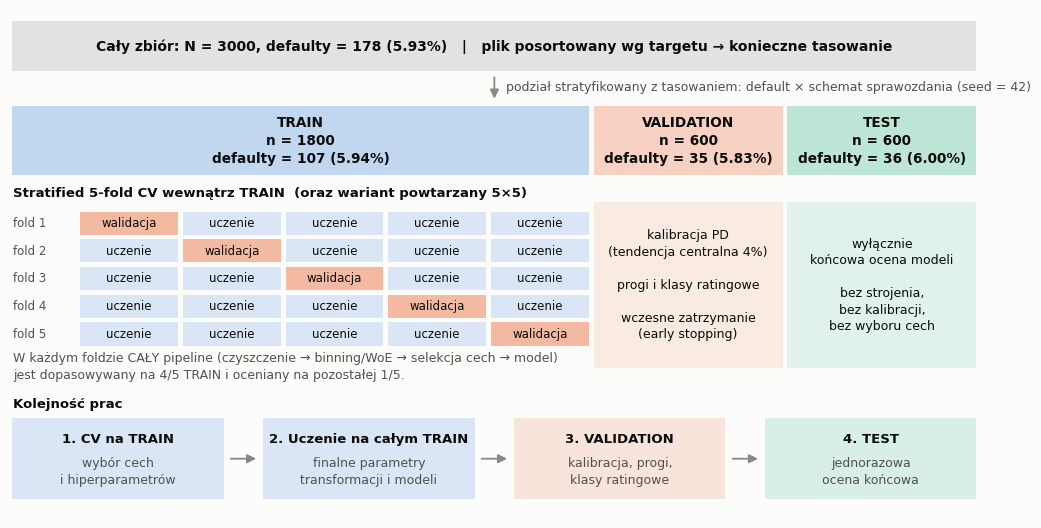

In [ ]:
fig, ax = plt.subplots(figsize=(12.5, 6.6))
ax.axis("off")
ax.set_xlim(0, 100)
ax.set_ylim(0, 66)
n = len(y_raw)
szer = lambda k: 100 * k / n


def pole(x, y, w, h, tekst, kolor, alpha=0.20, bold=False, fs=9.5):
    ax.add_patch(Rectangle((x + 0.25, y), w - 0.5, h, facecolor=kolor, alpha=alpha, edgecolor="none"))
    ax.text(x + w / 2, y + h / 2, tekst, ha="center", va="center", fontsize=fs, color=TUSZ, fontweight="bold" if bold else "normal", linespacing=1.35)


def strzalka(x0, y0, x1, y1):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=13, lw=1.3, color=SZARY))


# 1) cały zbiór
pole(0, 58, 100, 6.5, f"Cały zbiór: N = {n}, defaulty = {N_DEF} ({DR:.2%})   |   plik posortowany wg targetu → konieczne tasowanie", SZARY, 0.22, True, 10)
strzalka(50, 57.6, 50, 54.1)
ax.text(51.2, 55.9, f"podział stratyfikowany z tasowaniem: default × schemat sprawozdania (seed = {RNG_SEED})", fontsize=9, color=TUSZ2, va="center")

# 2) trzy zbiory (szerokość proporcjonalna do liczebności)
x0, lewe = 0, {}
for nazwa, yy, etykieta in [("train", y_train, "TRAIN"), ("valid", y_valid, "VALIDATION"), ("test", y_test, "TEST")]:
    w = szer(len(yy))
    pole(x0, 44.5, w, 9.0, f"{etykieta}\nn = {len(yy)}\ndefaulty = {int(yy.sum())} ({yy.mean():.2%})", KOL[nazwa], 0.28, True, 9.8)
    lewe[nazwa] = (x0, w)
    x0 += w

# 3) walidacja krzyżowa wewnątrz TRAIN
xt, wt = lewe["train"]
ax.text(xt + 0.3, 42.2, f"Stratified {N_SPLITS}-fold CV wewnątrz TRAIN  (oraz wariant powtarzany {N_SPLITS}×{N_REPEATS})", fontsize=9.5, fontweight="bold", va="center")
fw = (wt - 7) / N_SPLITS
for k in range(N_SPLITS):
    yk = 36.8 - k * 3.6
    ax.text(xt + 0.3, yk + 1.5, f"fold {k + 1}", fontsize=8.5, color=TUSZ2, va="center")
    for j in range(N_SPLITS):
        walid = j == k
        pole(xt + 7 + j * fw, yk, fw, 3.0, "walidacja" if walid else "uczenie", KOL["valid"] if walid else KOL["train"], 0.45 if walid else 0.16, False, 8.5)
ax.text(xt + 0.3, 19.6, "W każdym foldzie CAŁY pipeline (czyszczenie → binning/WoE → selekcja cech → model)\njest dopasowywany na 4/5 TRAIN i oceniany na pozostałej 1/5.",
        fontsize=9, color=TUSZ2, va="center", linespacing=1.4)

# 4) role zbiorów VALIDATION i TEST
xv, wv = lewe["valid"]
xs, ws = lewe["test"]
pole(xv, 19.5, wv, 21.5, "kalibracja PD\n(tendencja centralna 4%)\n\nprogi i klasy ratingowe\n\nwczesne zatrzymanie\n(early stopping)", KOL["valid"], 0.12, False, 9)
pole(xs, 19.5, ws, 21.5, "wyłącznie\nkońcowa ocena modeli\n\nbez strojenia,\nbez kalibracji,\nbez wyboru cech", KOL["test"], 0.12, False, 9)

# 5) kolejność prac
kroki = [("1. CV na TRAIN", "wybór cech\ni hiperparametrów", "train"), ("2. Uczenie na całym TRAIN", "finalne parametry\ntransformacji i modeli", "train"),
         ("3. VALIDATION", "kalibracja, progi,\nklasy ratingowe", "valid"), ("4. TEST", "jednorazowa\nocena końcowa", "test")]
odstep = 3.6
wk = (100 - odstep * (len(kroki) - 1)) / len(kroki)
for i, (tytul, opis, z) in enumerate(kroki):
    xk = i * (wk + odstep)
    pole(xk, 2.5, wk, 10.5, "", KOL[z], 0.16)
    ax.text(xk + wk / 2, 10.2, tytul, ha="center", va="center", fontsize=9.5, fontweight="bold")
    ax.text(xk + wk / 2, 6.0, opis, ha="center", va="center", fontsize=9, color=TUSZ2, linespacing=1.35)
    if i < len(kroki) - 1:
        strzalka(xk + wk + 0.2, 7.7, xk + wk + odstep - 0.2, 7.7)
ax.text(0.3, 14.8, "Kolejność prac", fontsize=9.5, fontweight="bold", va="center")

### 2.6. Opis schematu walidacji i zasady kontroli przecieku

**Role zbiorów**

| Zbiór | n / defaulty | Do czego służy | Czego na nim NIE robimy |
|---|---|---|---|
| `train` (60%) | 1800 / 107 | Data Quality, EDA, dopasowanie wszystkich transformacji, selekcja cech, uczenie modeli; w jego obrębie walidacja krzyżowa (strojenie) | — |
| `validation` (20%) | 600 / 36 | kalibracja PD do 4%, progi i klasy ratingowe, wczesne zatrzymanie, porównanie wariantów po strojeniu | nie dopasowujemy na nim cech, binningu ani WoE |
| `test` (20%) | 600 / 35 | jedna, końcowa ocena obu modeli (jakość predykcji, kalibracja, stabilność wyjaśnień) | niczego nie dopasowujemy i niczego na jego podstawie nie wybieramy |

**Zasady kontroli przecieku** (stosowane w całym projekcie; ich przestrzeganie jest testowane w ETAPIE 6)

| Krok | Na czym jest dopasowywany | Jak to egzekwujemy |
|---|---|---|
| Czyszczenie: usuwanie cech (duplikaty, braki, quasi-stałe), zera strukturalne, progi winsoryzacji, mediany, średnie i odchylenia | `train`, a w CV — część ucząca folda | transformery scikit-learn z metodami `fit`/`transform`, zawsze wewnątrz `Pipeline` |
| Binning, WoE, kodowanie kategorii | jw. (wymagają targetu, więc są szczególnie wrażliwe na przeciek) | jw. — krok `Pipeline`, nigdy „na całości przed CV” |
| Selekcja cech (IV, korelacje) | jw. | selekcja jest krokiem `Pipeline`, a nie operacją wykonaną raz przed walidacją |
| Strojenie hiperparametrów | CV wewnątrz `train` | `cv=FOLDY`, cały `Pipeline` jako estymator |
| Kalibracja, progi, klasy ratingowe | `validation` | osobny krok po zamrożeniu modelu |
| Ocena końcowa | `test` | jednorazowo, na końcu projektu |

Dodatkowe zabezpieczenia wynikające z ETAPU 1: indeks rekordu nie jest cechą (plik posortowany wg targetu), wszystkie podziały tasują dane, a przy pojawieniu się identyfikatora podmiotu podział i CV przełączają się na wariant grupowy (`GROUPS`).

**Ograniczenie.** Dane są przekrojowe, więc nie da się wykonać walidacji w czasie (out-of-time). Wszystkie oceny dotyczą tej samej populacji i tego samego okresu — stabilność modelu w czasie pozostaje poza zakresem tego, co można tu sprawdzić.

## ETAP 3. Jakość danych (Data Quality) i naprawa danych

Od tego miejsca wszystkie analizy wykonujemy na **zbiorze treningowym** — to na jego podstawie zapadają decyzje o czyszczeniu, a każda reguła, która wymaga „nauczenia się” czegoś z danych, zostaje zamknięta w transformerze z metodami `fit`/`transform` (p. 3.6).

### 3.1. Braki danych i wartości nieskończone

--- W zbiorze treningowym X_train: ---

Komórki z NaN: 12501 | komórki z inf: 587 (w tym -inf: 0) | cech z NaN lub inf: 10 z 220 | braków w kolumnach kategorycznych: 0
Obserwacji z co najmniej jednym NaN lub inf: 1779 z 1800


,NaN (%),inf (%),razem (%),liczba unikalnych wartości
RP_przeplywy_operacyjne,98.72,0.00,98.72,16
wsk_akt_generowania_got_2,98.72,0.00,98.72,16
wsk_zysk_CF_operacyjny,98.72,0.00,98.72,23
wsk_pokrycie_wyd_fin_gotowkowe_2,98.72,0.00,98.72,16
wsk_pokrycie_zob_kr_gotowkowe_2,98.72,0.00,98.72,16
wsk_zadluzenia_gotowki_2,98.72,0.00,98.72,12
RP_amortyzacja,95.78,0.00,95.78,59
wsk_plynnosc_biez_1,3.39,29.39,32.78,1210
wsk_struktura_kap_wlasnego_s_2,1.50,3.00,4.50,1622
wsk_kapital_do_aktywa,1.50,0.22,1.72,1600


Udział +inf w wsk_plynnosc_biez_1 wg schematu sprawozdania (%): {'SFJIN': 7.1, 'SFJMA': 7.4, 'SFJMI': 91.9}


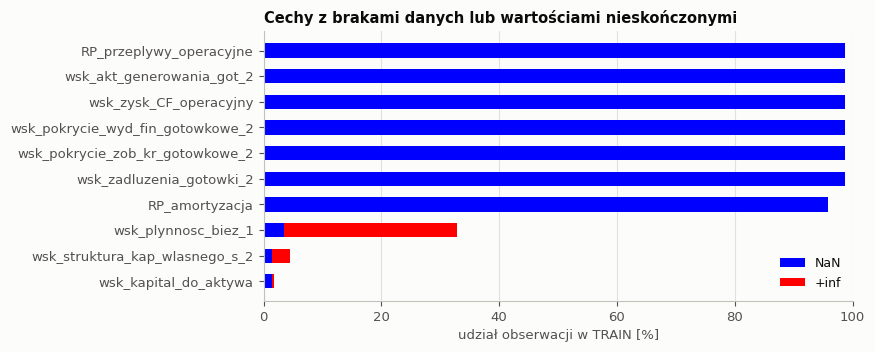

In [43]:
NUM_COLS = X_train.select_dtypes(include="number").columns.tolist()
CAT_COLS = X_train.select_dtypes(exclude="number").columns.tolist()

A_tr = X_train[NUM_COLS].to_numpy(dtype=float)
braki = pd.DataFrame({"NaN (%)": np.isnan(A_tr).mean(axis=0) * 100, "inf (%)": np.isinf(A_tr).mean(axis=0) * 100}, index=NUM_COLS)
braki["razem (%)"] = braki.sum(axis=1)
braki["liczba unikalnych wartości"] = X_train[NUM_COLS].nunique().to_numpy()
braki = braki[braki["razem (%)"] > 0].sort_values("razem (%)", ascending=False)

print("--- W zbiorze treningowym X_train: ---")
print(f"\nKomórki z NaN: {int(np.isnan(A_tr).sum())} | komórki z inf: {int(np.isinf(A_tr).sum())} (w tym -inf: {int(np.isneginf(A_tr).sum())})"
      f" | cech z NaN lub inf: {len(braki)} z {len(NUM_COLS)} | braków w kolumnach kategorycznych: {int(X_train[CAT_COLS].isna().sum().sum())}")
print("Obserwacji z co najmniej jednym NaN lub inf:", int((~np.isfinite(A_tr)).any(axis=1).sum()), "z", len(X_train))
display(braki.round(2))

fig, ax = plt.subplots(figsize=(7.6, 3.5))
t = braki.iloc[::-1]
ax.barh(t.index, t["NaN (%)"], height=0.55, color="blue", linewidth=1.5, label="NaN")
ax.barh(t.index, t["inf (%)"], left=t["NaN (%)"], height=0.55, color="red", linewidth=1.5, label="+inf")
ax.set(xlabel="udział obserwacji w TRAIN [%]", xlim=(0, 100), title="Cechy z brakami danych lub wartościami nieskończonymi")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")

inf_plynnosc = np.isinf(X_train["wsk_plynnosc_biez_1"]).groupby(X_train["schemat_wsk_bilans"]).mean() * 100
print("Udział +inf w wsk_plynnosc_biez_1 wg schematu sprawozdania (%):", inf_plynnosc.round(1).to_dict())

**Wnioski.**
* Braki są skoncentrowane w **10 z 217** cech liczbowych; pozostałe są kompletne. Siedem cech związanych z rachunkiem przepływów pieniężnych (`RP_*` i wskaźniki oparte na przepływach operacyjnych) ma ponad 95% braków — rachunek przepływów sporządza tylko niewielka część jednostek. Tych cech nie da się sensownie uzupełnić, więc zostaną usunięte.
* Wartości nieskończone występują w trzech wskaźnikach i są wyłącznie dodatnie — powstają z dzielenia przez zero. W `wsk_plynnosc_biez_1` dotyczy to aż 30% obserwacji, ale przede wszystkim jednostek mikro (92% z nich wobec 8–10% w pozostałych schematach). To pierwsza wskazówka, że „zero” w mianowniku nie zawsze jest prawdziwym zerem.
* Prawie każda obserwacja ma co najmniej jeden brak (cechy `RP_*`), więc usuwanie wierszy z brakami nie wchodzi w grę — pracujemy na poziomie cech.

### 3.2. Zera strukturalne a schemat sprawozdania

Braków formalnie jest mało, ale wiele pozycji ma bardzo duży udział zer. Sprawdzamy, czy zależy on od schematu sprawozdania.

In [44]:
X_num = X_train.select_dtypes(include="number").drop(columns=[TARGET], errors="ignore")
X_num_finite = X_num.replace([np.inf, -np.inf], np.nan)

liczba_obserwacji = X_num_finite.notna().sum()
liczba_zer = (X_num_finite == 0).sum()
udzial_zer = liczba_zer.div(liczba_obserwacji.replace(0, np.nan)) * 100

zera_df = pd.DataFrame({
    "liczba obserwacji": liczba_obserwacji,
    "liczba zer": liczba_zer,
    "udział zer (%)": udzial_zer,
    "liczba unikalnych wartości": X_num_finite.nunique()
})

zera_df = zera_df.sort_values("udział zer (%)", ascending=False)

print("Łączna liczba zer:", liczba_zer.sum())
print("Liczba cech zawierających zera:", (liczba_zer > 0).sum())

print("\n--- Cechy z udziałem zer > 90% ---")
duzo_zer = zera_df[zera_df["udział zer (%)"] > 90]

print("Liczba takich cech:", len(duzo_zer))
display(duzo_zer.round(2))

print("\n--- Wszystkie cechy zawierające zera ---")
display(zera_df[zera_df["liczba zer"] > 0].round(2))


Łączna liczba zer: 147556
Liczba cech zawierających zera: 215

--- Cechy z udziałem zer > 90% ---
Liczba takich cech: 33


,liczba obserwacji,liczba zer,udział zer (%),liczba unikalnych wartości
Naleznosci_dostaw_uslug_pow12m_kapitale,1800,1799,99.94,2
Zobowiazania_dostaw_uslug_pow12m_kapitale,1800,1799,99.94,2
Ujemna_wartosc_firmy,1800,1798,99.89,3
Naleznosci_dostaw_uslug_pow12m_powiazane,1800,1798,99.89,3
Zobowiazania_dostaw_uslug_pow12m_powiazane,1800,1797,99.83,4
Pozostale_rezerwy,1800,1790,99.44,11
Zobowiazania_dostaw_uslug_pow12m,1800,1788,99.33,13
Zobowiazania_dostaw_uslug_12m_kapitale,1800,1788,99.33,13
Wartosc_firmy,1800,1782,99.00,19
Zobowiazania_dostaw_uslug_pow12m_pozostale,1800,1781,98.94,20



--- Wszystkie cechy zawierające zera ---


,liczba obserwacji,liczba zer,udział zer (%),liczba unikalnych wartości
Naleznosci_dostaw_uslug_pow12m_kapitale,1800,1799,99.94,2
Zobowiazania_dostaw_uslug_pow12m_kapitale,1800,1799,99.94,2
Ujemna_wartosc_firmy,1800,1798,99.89,3
Naleznosci_dostaw_uslug_pow12m_powiazane,1800,1798,99.89,3
Zobowiazania_dostaw_uslug_pow12m_powiazane,1800,1797,99.83,4
...,...,...,...,...
wsk_struktura_kap_wlasnego_s_2,1719,17,0.99,1621
wsk_kapital_do_aktywa,1769,17,0.96,1599
wsk_index_aktywne,1800,3,0.17,894
wsk_plynnosc_biez_1,1210,2,0.17,1209


### 3.4. Spójność księgowa, wartości ujemne i sprawozdania puste

In [19]:
def spelniona(lewa, prawa, tol=1.0):
    r = (lewa - prawa).abs()
    return (r <= tol) | (r <= 1e-4 * lewa.abs())


T = X_train
tozsamosci = pd.DataFrame({
    "Aktywa = aktywa trwałe + aktywa obrotowe": spelniona(T["Aktywa"], T["Aktywa_trwale"] + T["Aktywa_obrotowe"]),
    "Aktywa = kapitał własny + zobowiązania i rezerwy": spelniona(T["Aktywa"], T["Kapital_wlasny"] + T["Zobowiazania_rezerwy"]),
    "Zysk netto w bilansie = zysk netto w RZiS": spelniona(T["Zysk_netto"], T["zysk_netto"]),
    "Zysk netto = zysk brutto − podatek dochodowy": spelniona(T["zysk_netto"], T["zysk_brutto"] - T["podatek_dochodowy"]),
    "Zysk operacyjny = zysk ze sprzedaży + pozost. przychody − pozost. koszty": spelniona(T["zysk_operacyjny"], T["zysk_sprzedazy"] + T["pozostale_przychody_oper"] - T["koszty_operacyjne_pozostale"]),
    "Przychody = sprzedaż + pozostałe operacyjne + finansowe": spelniona(T["przychody"], T["przychody_sprzedazy"] + T["pozostale_przychody_oper"] + T["przychody_finansowe"]),
})
tab = (tozsamosci.groupby(T["schemat_wsk_bilans"]).mean() * 100).T[schematy].copy()
tab["razem"] = tozsamosci.mean() * 100
print("---Odsetek sprawozdań spełniających tożsamość (%)---")
display(tab.round(1))

nieujemne = ["Aktywa", "Aktywa_trwale", "Aktywa_obrotowe", "Zapasy", "Naleznosci_krotkoterminowe", "Srodki_pieniezne", "Kapital_podstawowy",
             "Zobowiazania_rezerwy", "Zobowiazania_krotkoterminowe", "przychody_sprzedazy", "koszty_operacyjne", "amortyzacja"]
anomalie = {
    "wartość ujemna w pozycji z natury nieujemnej (12 pozycji)": (T[nieujemne] < 0).any(axis=1),
    "sprawozdanie puste: Aktywa = 0": T["Aktywa"] == 0,
    "brak przychodów: przychody = 0": T["przychody"] == 0,
    "spółka „uśpiona”: brak przychodów i kosztów operacyjnych": (T["przychody"] == 0) & (T["koszty_operacyjne"] == 0),
    "aktywa > 0, ale brak pasywów (kapitał własny = 0 i zobowiązania = 0)": (T["Aktywa"] > 0) & (T["Kapital_wlasny"] == 0) & (T["Zobowiazania_rezerwy"] == 0),
    "ujemny kapitał własny": T["Kapital_wlasny"] < 0,
}
display(pd.DataFrame({"liczba obserwacji": {k: int(v.sum()) for k, v in anomalie.items()},
                      "udział w TRAIN (%)": {k: round(v.mean() * 100, 2) for k, v in anomalie.items()}}))

---Odsetek sprawozdań spełniających tożsamość (%)---


schemat_wsk_bilans,SFJIN,SFJMA,SFJMI,razem
Aktywa = aktywa trwałe + aktywa obrotowe,98.1,96.8,92.0,96.2
Aktywa = kapitał własny + zobowiązania i rezerwy,96.6,95.5,93.9,95.7
Zysk netto w bilansie = zysk netto w RZiS,95.9,93.4,98.1,95.9
Zysk netto = zysk brutto − podatek dochodowy,96.7,97.9,58.3,86.8
Zysk operacyjny = zysk ze sprzedaży + pozost. przychody − pozost. koszty,98.8,100.0,99.6,99.3
Przychody = sprzedaż + pozostałe operacyjne + finansowe,100.0,100.0,100.0,100.0


,liczba obserwacji,udział w TRAIN (%)
wartość ujemna w pozycji z natury nieujemnej (12 pozycji),12,0.67
sprawozdanie puste: Aktywa = 0,25,1.39
brak przychodów: przychody = 0,282,15.67
spółka „uśpiona”: brak przychodów i kosztów operacyjnych,208,11.56
"aktywa > 0, ale brak pasywów (kapitał własny = 0 i zobowiązania = 0)",22,1.22
ujemny kapitał własny,1,0.06


**Wnioski.**
* W sprawozdaniach jednostek „innych” i małych tożsamości księgowe są spełnione w 93–100% przypadków; pozostałe kilka procent to sprawozdania niespójne lub niekompletne. U jednostek mikro część tożsamości z definicji nie może być spełniona (brakujące pozycje — p. 3.2).
* Wartości ujemne w pozycjach z natury nieujemnych są incydentalne (12 obserwacji). Zwraca uwagę niemal całkowity brak ujemnego kapitału własnego — zbiór wygląda na wstępnie przetworzony.
* Ok. 16% spółek nie wykazuje przychodów (12% nie ma też kosztów operacyjnych — spółki „uśpione”), a 1,4% ma sprawozdanie puste. Dla tych firm wskaźniki finansowe nie niosą informacji i model może się opierać głównie na cechach rejestrowych i cechach otoczenia.
* **Decyzja:** nie usuwamy obserwacji. Takie przypadki będą trafiać do modelu również po wdrożeniu, a arbitralne ich usuwanie zmieniłoby populację i poziom ryzyka. Niespójności neutralizujemy na poziomie cech (wartości specjalne → brak danych, koszyki, capping) i odnotowujemy jako ograniczenie; w ocenie modeli warto będzie pokazać wyniki osobno dla jednostek mikro.

### 3.5. Obserwacje odstające

In [20]:
Xo = X_train[KWOTY + WSK_KWOTOWE + WSKAZNIKI].replace([np.inf, -np.inf], np.nan)
q = Xo.quantile([0.01, 0.25, 0.50, 0.75, 0.99])
iqr = q.loc[0.75] - q.loc[0.25]
ogony = pd.DataFrame({
    "typ": [typ_zmiennej(c) for c in Xo.columns],
    "skośność": Xo.skew(),
    "obs. poza Q1−3·IQR, Q3+3·IQR (%)": ((Xo < q.loc[0.25] - 3 * iqr) | (Xo > q.loc[0.75] + 3 * iqr)).mean() * 100,
    "max |x| / p99 |x|": Xo.abs().max() / Xo.abs().quantile(0.99).replace(0, np.nan),
})
display(ogony.groupby("typ").agg(**{"liczba cech": ("skośność", "size"), "mediana |skośności|": ("skośność", lambda s: s.abs().median()),
                                    "mediana udziału obs. skrajnych (%)": ("obs. poza Q1−3·IQR, Q3+3·IQR (%)", "median"),
                                    "mediana max/p99": ("max |x| / p99 |x|", "median")}).round(1))
print("---Wskaźniki o najbardziej skrajnych wartościach---")
skrajne = ogony[ogony["typ"] == "wskaźnik (iloraz)"].sort_values("max |x| / p99 |x|", ascending=False).head(6).index
display(pd.DataFrame({"mediana": Xo[skrajne].median(), "p99": Xo[skrajne].quantile(0.99), "maksimum": Xo[skrajne].max(),
                      "formuła (z danych)": META.loc[skrajne, "formuła (z danych)"]}).round(2))

,liczba cech,mediana |skośności|,mediana udziału obs. skrajnych (%),mediana max/p99
typ,,,,
pozycja kwotowa [zł],87,19.1,8.8,11.8
wskaźnik (iloraz),126,28.8,13.5,109.0


---Wskaźniki o najbardziej skrajnych wartościach---


,mediana,p99,maksimum,formuła (z danych)
wsk_struktura_kap_wlasnego_s_2,0.77,29.08,2.845077e+15,
wsk_rotacja_aktywow_1,1.08,94.06,3.435974e+14,
wsk_pokrycia_zobowiazan_rz_aktywami_trwalymi,0.00,31352.00,7.504750e+15,Rzeczowe_aktywa_trwale / wsk_Zobowiazania_dlugoterminowe
wsk_zadluzenie_gotowka,0.00,1.08,2.821056e+04,koszty_odsetki / przychody_sprzedazy
wsk_koszty_odsetki_przychody,0.00,1.08,2.821056e+04,koszty_odsetki / przychody_sprzedazy
wsk_obrotowsci_naleznosci,4.01,3119.36,1.794000e+07,przychody_sprzedazy / Naleznosci_krotkoterminowe


**Wnioski.** Rozkłady są skrajnie skośne, a wartości odstające nie są incydentem, lecz regułą: w typowej pozycji kwotowej ok. 9%, a w typowym wskaźniku ok. 13% obserwacji leży poza „szerokimi” płotkami Tukeya (3·IQR); maksimum przekracza 99. percentyl kilkanaście razy w kwotach i ponad sto razy we wskaźnikach (pojedyncze wartości sięgają rzędu 10¹⁵). W pozycjach kwotowych to naturalny efekt skali firm (od spółek z kapitałem 5 tys. zł po podmioty z aktywami rzędu setek mln zł); we wskaźnikach — głównie skutek małych i zerowych mianowników (p. 3.3).

**Polityka wobec obserwacji odstających (capping/outlier policy):**
* obserwacji **nie usuwamy** — skrajne wartości niosą informację o ryzyku i będą występować po wdrożeniu;
* **model interpretowalny:** binning — wartości skrajne trafiają do skrajnych koszyków (krańcowe koszyki są otwarte: od −∞ i do +∞), więc nie mają nieproporcjonalnego wpływu ani przy uczeniu, ani przy scoringu;
* **model black-box i każdy model na cechach surowych:** winsoryzacja do percentyli 1–99 wyznaczonych **na zbiorze uczącym**; dla modeli drzewiastych nie zmienia ona podziałów, ale stabilizuje wykresy PDP/ICE/ALE i chroni przed wartościami spoza zakresu uczenia;
* **modele wrażliwe na skalę (SVM, sieć):** dodatkowo logarytm ze znakiem (rozkłady rozciągają się na wiele rzędów wielkości) i standaryzacja liczona po winsoryzacji — średnia i odchylenie nie są odporne na obserwacje skrajne.

### 3.6. Transformery czyszczące

Wszystkie decyzje z p. 3.1–3.5 zamykamy w trzech transformerach zgodnych ze scikit-learn. Każdy uczy się wyłącznie w `fit` (na zbiorze uczącym lub części uczącej folda), a w `transform` jedynie stosuje zapamiętane reguły.

In [21]:
# --- słowniki do zmiennych kategorycznych (stałe, nie zależą od danych) --------------------------------
PKD_SEKCJE = [("A", 1, 3, "Rolnictwo, leśnictwo, rybactwo"), ("B", 5, 9, "Górnictwo i wydobywanie"),
              ("C", 10, 33, "Przetwórstwo przemysłowe"), ("D", 35, 35, "Energia, gaz, para wodna"),
              ("E", 36, 39, "Woda, ścieki, odpady"), ("F", 41, 43, "Budownictwo"), ("G", 45, 47, "Handel hurtowy i detaliczny"),
              ("H", 49, 53, "Transport i magazynowanie"), ("I", 55, 56, "Zakwaterowanie i gastronomia"),
              ("J", 58, 63, "Informacja i komunikacja"), ("K", 64, 66, "Finanse i ubezpieczenia"),
              ("L", 68, 68, "Obsługa rynku nieruchomości"), ("M", 69, 75, "Działalność profesjonalna i naukowa"),
              ("N", 77, 82, "Administrowanie i usługi wspierające"), ("O", 84, 84, "Administracja publiczna"), ("P", 85, 85, "Edukacja"),
              ("Q", 86, 88, "Opieka zdrowotna i pomoc społeczna"), ("R", 90, 93, "Kultura, rozrywka i rekreacja"),
              ("S", 94, 96, "Pozostałe usługi"), ("T", 97, 98, "Gospodarstwa domowe"), ("U", 99, 99, "Organizacje eksterytorialne")]   # sekcje PKD 2007 (nazwy skrócone)
DZIAL_NA_SEKCJE = {dzial: sekcja for sekcja, od, do, _ in PKD_SEKCJE for dzial in range(od, do + 1)}
SEKCJA_OPIS = {sekcja: opis for sekcja, _, _, opis in PKD_SEKCJE}


def pkd_sekcja(kod):
    """Kod PKD 2007 wczytany jako liczba (np. 113 = '0113', 4120) -> litera sekcji. Dział = kod // 100, czyli 2 pierwsze cyfry kodu 4-cyfrowego."""
    dzial = np.asarray(kod, dtype="int64") // 100
    return np.array([DZIAL_NA_SEKCJE.get(int(d), "?") for d in dzial], dtype=object)


def grupa_wlasnosci(kod):
    """Symbol formy własności -> grupa. Interpretacja symboli wg klasyfikacji form własności REGON (1xx sektor publiczny,
    2xx prywatny; x1x własność jednorodna, pozostałe mieszana; 0 = brak symbolu) - do potwierdzenia w dokumencie opisu zmiennych."""
    k = np.asarray(kod, dtype="int64")
    out = np.full(len(k), "publiczna_lub_miedzysektorowa", dtype=object)
    out[k == 0] = "brak_danych"
    out[k == 214] = "krajowe_osoby_fizyczne"
    out[k == 215] = "krajowa_prywatna_pozostala"
    out[k == 216] = "zagraniczna"
    out[(k >= 220) & (k <= 229)] = "prywatna_mieszana"
    return out


class CategoryPreparer(TransformerMixin, BaseEstimator):
    """Kody i schematy -> czytelne zmienne kategoryczne (tekstowe).

    pkdKod -> pkd_sekcja, formaWlasnosci_Symbol -> forma_wlasnosci, schemat_wsk_* -> schemat_*; szczegolnaFormaPrawna_Symbol (stała) jest usuwana.
    Poziomy rzadsze niż `min_count` obserwacji w zbiorze uczącym oraz poziomy nieznane w `transform` trafiają do klasy `other_label`.
    """
    SUROWE = ["pkdKod", "formaWlasnosci_Symbol", "szczegolnaFormaPrawna_Symbol", "schemat_wsk_bilans", "schemat_wsk_rzis"]

    def __init__(self, min_count=30, other_label="INNE"):
        self.min_count = min_count
        self.other_label = other_label

    @staticmethod
    def _kategorie(X):
        return pd.DataFrame({"pkd_sekcja": pkd_sekcja(X["pkdKod"]), "forma_wlasnosci": grupa_wlasnosci(X["formaWlasnosci_Symbol"]),
                             "schemat_bilans": X["schemat_wsk_bilans"].astype(str).to_numpy(),
                             "schemat_rzis": X["schemat_wsk_rzis"].astype(str).to_numpy()}, index=X.index)

    def fit(self, X, y=None):
        C = self._kategorie(X)
        self.levels_ = {}
        for c in C.columns:
            licznosci = C[c].value_counts()
            self.levels_[c] = sorted(licznosci[licznosci >= self.min_count].index.tolist())
        self.cat_cols_ = C.columns.tolist()
        return self

    def transform(self, X):
        C = self._kategorie(X)
        for c in C.columns:
            v = C[c].to_numpy(dtype=object)
            C[c] = np.where(np.isin(v, self.levels_[c]), v, self.other_label)
        return pd.concat([C, X.drop(columns=[c for c in self.SUROWE if c in X.columns])], axis=1)


class SpecialValueRecoder(TransformerMixin, BaseEstimator):
    """Wartości specjalne -> brak danych (NaN).

    1) +/-inf (iloraz nieokreślony);
    2) zera strukturalne: jeżeli w danym schemacie sprawozdania cecha jest zerem w >= `thr` obserwacji zbioru uczącego,
       a w innym schemacie jest „żywa” (udział zer < `thr_alive`), to zero znaczy tam „pozycja nieraportowana”;
    3) ilorazy o zerowym mianowniku - dla wskaźników o znanej formule `formulas` = {wskaźnik: (licznik, mianownik)}.
    Reguły 1 i 3 są wierszowe (niczego się nie uczą); reguła 2 jest wyznaczana w `fit`, wyłącznie na zbiorze uczącym.
    """

    def __init__(self, schema_cols=("schemat_bilans", "schemat_rzis"), thr=0.95, thr_alive=0.80, min_group=50, formulas=None):
        self.schema_cols = schema_cols
        self.thr = thr
        self.thr_alive = thr_alive
        self.min_group = min_group
        self.formulas = formulas

    def fit(self, X, y=None):
        self.num_cols_ = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
        zero = X[self.num_cols_].to_numpy(dtype=float) == 0
        self.rules_ = []                                               # (kolumna schematu, poziom, indeksy cech)
        for sc in self.schema_cols:
            s = X[sc].astype(str).to_numpy()
            poziomy = [p for p in sorted(set(s)) if (s == p).sum() >= self.min_group]
            if len(poziomy) < 2:
                continue
            udzial_zer = np.vstack([zero[s == p].mean(axis=0) for p in poziomy])       # (poziomy, cechy)
            for i, p in enumerate(poziomy):
                zywa_gdzie_indziej = np.delete(udzial_zer, i, axis=0).min(axis=0) < self.thr_alive
                idx = np.flatnonzero((udzial_zer[i] >= self.thr) & zywa_gdzie_indziej)
                if len(idx):
                    self.rules_.append((sc, p, idx))
        return self

    def transform(self, X):
        A = X[self.num_cols_].to_numpy(dtype=float, copy=True)
        pozycja = {c: j for j, c in enumerate(self.num_cols_)}
        zero_surowe = A == 0
        A[~np.isfinite(A)] = np.nan                                                    # (1)
        for sc, p, idx in self.rules_:                                                 # (2)
            wiersze = np.flatnonzero(X[sc].astype(str).to_numpy() == p)
            if len(wiersze):
                blok = A[np.ix_(wiersze, idx)]
                blok[blok == 0] = np.nan
                A[np.ix_(wiersze, idx)] = blok
        for wsk, (_, mianownik) in (self.formulas or {}).items():                      # (3)
            if wsk in pozycja and mianownik in pozycja:
                A[zero_surowe[:, pozycja[mianownik]], pozycja[wsk]] = np.nan
        return pd.concat([X.drop(columns=self.num_cols_), pd.DataFrame(A, index=X.index, columns=self.num_cols_)], axis=1)

    def rules_table(self):
        return pd.DataFrame([{"schemat": sc, "poziom": p, "liczba cech": len(idx), "przykłady": ", ".join(self.num_cols_[i] for i in idx[:4])}
                             for sc, p, idx in self.rules_])


class FinancialCleaner(TransformerMixin, BaseEstimator):
    """Czyszczenie cech liczbowych (kolumny nieliczbowe przechodzą bez zmian). Wszystkie parametry wyznaczane w `fit`:

    1. inf -> NaN,
    2. (opcjonalnie) logarytm ze znakiem, sign(x) * log(1 + |x|), dla kolumn `log_cols` (lista nazw albo "all"),
    3. usunięcie cech zduplikowanych, cech z ponad `max_missing` braków i cech quasi-stałych (dominanta >= `quasi_const`),
    4. (opcjonalnie) winsoryzacja do kwantyli `winsor` = (dolny, górny); cechy, które po niej stają się stałe, są usuwane,
    5. (opcjonalnie) imputacja medianą + flagi braku `__brak` dla cech z co najmniej `indicator_min` braków (bez powtórzonych wzorców),
    6. (opcjonalnie) standaryzacja (średnia i odchylenie liczone po winsoryzacji i imputacji).
    """

    def __init__(self, max_missing=0.90, quasi_const=0.99, winsor=(0.01, 0.99), log_cols=None, impute=True, indicator_min=0.02, scale=False):
        self.max_missing = max_missing
        self.quasi_const = quasi_const
        self.winsor = winsor
        self.log_cols = log_cols
        self.impute = impute
        self.indicator_min = indicator_min
        self.scale = scale

    def _liczbowe(self, X, cols):
        A = X[cols].to_numpy(dtype=float, copy=True)
        A[~np.isfinite(A)] = np.nan                                                    # 1
        if self.log_cols is not None:                                                  # 2
            for j, c in enumerate(cols):
                if self.log_cols == "all" or c in self.log_cols:
                    A[:, j] = np.sign(A[:, j]) * np.log1p(np.abs(A[:, j]))
        return pd.DataFrame(A, index=X.index, columns=cols)

    def fit(self, X, y=None):
        num_in = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
        self.pass_cols_ = [c for c in X.columns if c not in num_in]
        A = self._liczbowe(X, num_in)
        duplikaty = A.columns[A.T.duplicated()].tolist()                               # 3
        A = A.drop(columns=duplikaty)
        udzial_brakow = A.isna().mean()
        za_duzo_brakow = udzial_brakow[udzial_brakow > self.max_missing].index.tolist()
        A = A.drop(columns=za_duzo_brakow)
        dominanta = A.apply(lambda s: s.value_counts(normalize=True).iloc[0])
        quasi_stale = dominanta[dominanta >= self.quasi_const].index.tolist()
        A = A.drop(columns=quasi_stale)
        self.dropped_ = {"duplikaty": duplikaty, "za dużo braków": za_duzo_brakow, "quasi-stałe": quasi_stale}
        if self.winsor is not None:                                                    # 4
            self.lo_, self.hi_ = A.quantile(self.winsor[0]), A.quantile(self.winsor[1])
            stale_po_cappingu = self.lo_.index[self.lo_ == self.hi_].tolist()          # cała zmienność leżała w odciętych ogonach
            self.lo_, self.hi_ = self.lo_.drop(stale_po_cappingu), self.hi_.drop(stale_po_cappingu)
            A = A.drop(columns=stale_po_cappingu).clip(lower=self.lo_, upper=self.hi_, axis=1)
            self.dropped_["stałe po winsoryzacji"] = stale_po_cappingu
        self.cols_ = A.columns.tolist()
        self.median_ = A.median()                                                      # 5
        self.ind_cols_ = [c for c in self.cols_ if udzial_brakow[c] >= self.indicator_min] if self.impute else []
        if self.ind_cols_:                                   # identyczne wzorce braków wnoszą tę samą informację - zostaje jedna flaga
            wzorce = A[self.ind_cols_].isna()
            self.ind_cols_ = wzorce.columns[~wzorce.T.duplicated()].tolist()
        if self.impute:
            A = A.fillna(self.median_)
        self.mean_, self.std_ = A.mean(), A.std(ddof=0).replace(0, 1.0)               # 6
        return self

    def transform(self, X):
        A = self._liczbowe(X, self.cols_)
        flagi = A[self.ind_cols_].isna().astype(int).add_suffix("__brak")
        if self.winsor is not None:
            A = A.clip(lower=self.lo_, upper=self.hi_, axis=1)
        if self.impute:
            A = A.fillna(self.median_)
        if self.scale:
            A = (A - self.mean_) / self.std_
        return pd.concat([X[self.pass_cols_], A, flagi], axis=1)

### 3.7. Dopasowanie czyszczenia na zbiorze treningowym

Dopasowujemy wariant „diagnostyczny” (bez winsoryzacji i imputacji) — jego wynik, `X_eda`, jest podstawą EDA w ETAPIE 4.

In [22]:
czyszczenie = Pipeline([("kategorie", CategoryPreparer(min_count=30)),
                        ("wartosci_specjalne", SpecialValueRecoder(formulas=REGULA_MIANOWNIKA)),
                        ("czyszczenie", FinancialCleaner(winsor=None, impute=False))])
X_eda = czyszczenie.fit_transform(X_train, y_train)
kat, spec, fc = czyszczenie.named_steps["kategorie"], czyszczenie.named_steps["wartosci_specjalne"], czyszczenie.named_steps["czyszczenie"]
KAT_EDA = kat.cat_cols_
NUM_EDA = fc.cols_

print("---Kategorie po przygotowaniu (poziomy z >= 30 obserwacjami w TRAIN; pozostałe -> INNE)---")
for c in KAT_EDA:
    print(f"  {c}: {kat.levels_[c]}")
print("  kody PKD, których dział nie należy do PKD 2007:", int((pkd_sekcja(X_raw["pkdKod"]) == "?").sum()))

print("\n---Zera strukturalne wykryte na TRAIN---")
display(spec.rules_table())
przed = int((~np.isfinite(X_train[num_cols].to_numpy(dtype=float))).sum())
po_spec = spec.transform(kat.transform(X_train))
po = int(po_spec[spec.num_cols_].isna().sum().sum())
print(f"Komórki oznaczone jako brak danych: {przed} przed -> {po} po rekodowaniu wartości specjalnych ({po / (len(X_train) * len(spec.num_cols_)):.1%} komórek liczbowych)")

print("\n---Cechy usunięte---")
for powod, lista in fc.dropped_.items():
    print(f"  {powod} ({len(lista)}): {', '.join(lista)}")
A_spec = po_spec[spec.num_cols_]
pary = []
for d in fc.dropped_["duplikaty"]:
    oryginal = next(c for c in spec.num_cols_ if c != d and c not in fc.dropped_["duplikaty"]
                    and np.array_equal(A_spec[c].to_numpy(), A_spec[d].to_numpy(), equal_nan=True))
    pary.append({"cecha będąca duplikatem": d, "cecha właściwa": oryginal, "formuła (z danych)": META.at[oryginal, "formuła (z danych)"]})
display(pd.DataFrame(pary))
print(f"Wymiar po czyszczeniu: {X_eda.shape} = {len(KAT_EDA)} cechy kategoryczne + {len(NUM_EDA)} cech liczbowych (z {len(num_cols)})")

---Kategorie po przygotowaniu (poziomy z >= 30 obserwacjami w TRAIN; pozostałe -> INNE)---
  pkd_sekcja: ['A', 'C', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'Q']
  forma_wlasnosci: ['brak_danych', 'krajowa_prywatna_pozostala', 'krajowe_osoby_fizyczne', 'prywatna_mieszana', 'publiczna_lub_miedzysektorowa', 'zagraniczna']
  schemat_bilans: ['SFJIN', 'SFJMA', 'SFJMI']
  schemat_rzis: ['SFJIN', 'SFJMA', 'SFJMI']
  kody PKD, których dział nie należy do PKD 2007: 0

---Zera strukturalne wykryte na TRAIN---


,schemat,poziom,liczba cech,przykłady
0,schemat_bilans,SFJIN,3,"Naleznosci_dostaw_uslug_12m, Zobowiazania_dostaw_uslug_12m, Kredyty_pozyczki"
1,schemat_bilans,SFJMA,5,"Naleznosci_dostaw_uslug_12m_pozostale, Zobowiazania_dostaw_uslug_12m_pozostale, Inne_r..."
2,schemat_bilans,SFJMI,61,"Rzeczowe_aktywa_trwale, Srodki_trwale, Inwestycje_dlugoterminowe, Naleznosci_dostaw_us..."
3,schemat_rzis,SFJIN,3,"Naleznosci_dostaw_uslug_12m, Zobowiazania_dostaw_uslug_12m, Kredyty_pozyczki"
4,schemat_rzis,SFJMA,5,"Naleznosci_dostaw_uslug_12m_pozostale, Zobowiazania_dostaw_uslug_12m_pozostale, Inne_r..."
5,schemat_rzis,SFJMI,61,"Rzeczowe_aktywa_trwale, Srodki_trwale, Inwestycje_dlugoterminowe, Naleznosci_dostaw_us..."


Komórki oznaczone jako brak danych: 13138 przed -> 71081 po rekodowaniu wartości specjalnych (18.2% komórek liczbowych)

---Cechy usunięte---
  duplikaty (9): wsk_rent_sprzedazy, wsk_zysk_operacyjny_zob_1, wsk_zadluzenie_gotowka, wsk_udzial_kap_wlasnego_aktywa_1, wsk_ebitda_zobowiazan_odsetki_1, wsk_ebitda_zobowiazan_odsetki_2, wsk_poziom_kosztow_operacyjnych, wsk_poziom_kosztow_finansowych, wsk_struktura_kap_wlasnego_1
  za dużo braków (7): RP_przeplywy_operacyjne, RP_amortyzacja, wsk_akt_generowania_got_2, wsk_pokrycie_wyd_fin_gotowkowe_2, wsk_pokrycie_zob_kr_gotowkowe_2, wsk_zadluzenia_gotowki_2, wsk_zysk_CF_operacyjny
  quasi-stałe (8): Naleznosci_dostaw_uslug_pow12m_powiazane, Naleznosci_dostaw_uslug_pow12m_kapitale, Pozostale_rezerwy, Zobowiazania_dostaw_uslug_pow12m_powiazane, Zobowiazania_dostaw_uslug_12m_kapitale, Zobowiazania_dostaw_uslug_pow12m_kapitale, Ujemna_wartosc_firmy, Zobowiazania_dostaw_uslug_pow12m


,cecha będąca duplikatem,cecha właściwa,formuła (z danych)
0,wsk_rent_sprzedazy,wsk_ROS,zysk_netto / przychody_sprzedazy
1,wsk_zysk_operacyjny_zob_1,wsk_zysk_op_zobowiazania,zysk_operacyjny / wsk_Zobowiazania_krotkoterminowe
2,wsk_zadluzenie_gotowka,wsk_koszty_odsetki_przychody,koszty_odsetki / przychody_sprzedazy
3,wsk_udzial_kap_wlasnego_aktywa_1,wsk_kapital_do_aktywa,Kapital_wlasny / Aktywa
4,wsk_ebitda_zobowiazan_odsetki_1,wsk_ebitda_koszty_odsetkowe_1,wsk_ebitda_1 / koszty_odsetki
5,wsk_ebitda_zobowiazan_odsetki_2,wsk_ebitda_koszty_odsetkowe_2,wsk_ebitda_2 / koszty_odsetki
6,wsk_poziom_kosztow_operacyjnych,wsk_koszty_przychody,wsk_koszty_operacyjne / przychody_sprzedazy
7,wsk_poziom_kosztow_finansowych,wsk_koszty_fin_przychody,koszty_finansowe / przychody_sprzedazy
8,wsk_struktura_kap_wlasnego_1,wsk_kapital_do_aktywa,Kapital_wlasny / Aktywa


Wymiar po czyszczeniu: (1800, 197) = 4 cechy kategoryczne + 193 cech liczbowych (z 217)


### 3.8. Podsumowanie jakości danych

| Problem | Skala (TRAIN) | Decyzja | Gdzie w kodzie |
|---|---|---|---|
| Plik posortowany wg targetu | cały zbiór | tasowanie przy każdym podziale; indeks nie jest cechą | ETAP 2 |
| Kody liczbowe (`pkdKod`, forma własności) | 378 kodów PKD, 18 form własności | sekcja PKD (z kodu 4-cyfrowego), grupy form własności, rzadkie poziomy → `INNE` | `CategoryPreparer` |
| Kolumna stała | `szczegolnaFormaPrawna_Symbol` = 117 | usunięcie | `CategoryPreparer` |
| Braki > 90% | 7 cech (przepływy pieniężne) | usunięcie cech | `FinancialCleaner` |
| Wartości nieskończone | 3 wskaźniki, do 30% obserwacji | → brak danych | `SpecialValueRecoder` |
| Zera strukturalne | 61 cech u jednostek mikro (oraz 3–5 w pozostałych schematach) | → brak danych (reguła uczona na zbiorze uczącym) | `SpecialValueRecoder` |
| Ilorazy o zerowym mianowniku (= licznik/100) | 73 wskaźniki o potwierdzonej formule; typowo ok. 1/5 obserwacji | → brak danych (reguła wierszowa) | `SpecialValueRecoder` |
| Cechy zduplikowane | 9 (8 dokładnych kopii + 1 po ujednoliceniu wartości specjalnych) | usunięcie kopii | `FinancialCleaner` |
| Cechy quasi-stałe (dominanta ≥ 99%) | 8 pozycji | usunięcie | `FinancialCleaner` |
| Obserwacje odstające | większość cech liczbowych | binning (model interpretowalny) / winsoryzacja 1–99% (cechy surowe) | `WoEEncoder`, `FinancialCleaner` |
| Niespójne i puste sprawozdania | kilka % obserwacji | obserwacje zostają; ograniczenie odnotowane | — |
| Słownik niepełny i miejscami nieprecyzyjny | 49 kolumn bez opisu | formuły odtworzone z danych; `wsk_index_*` pod obserwacją | p. 3.3, 6.2 |

## ETAP 4. Eksploracyjna analiza danych (EDA)

EDA wykonujemy na `X_eda` (zbiór treningowy po czyszczeniu z ETAPU 3: wartości specjalne zamienione na braki, usunięte cechy zbędne) oraz `y_train`. Zbiory `validation` i `test` nie biorą w niej udziału — wszystko, czego się tu dowiemy o związku cech z targetem, pochodzi z danych uczących.

### 4.1. Rozkłady cech

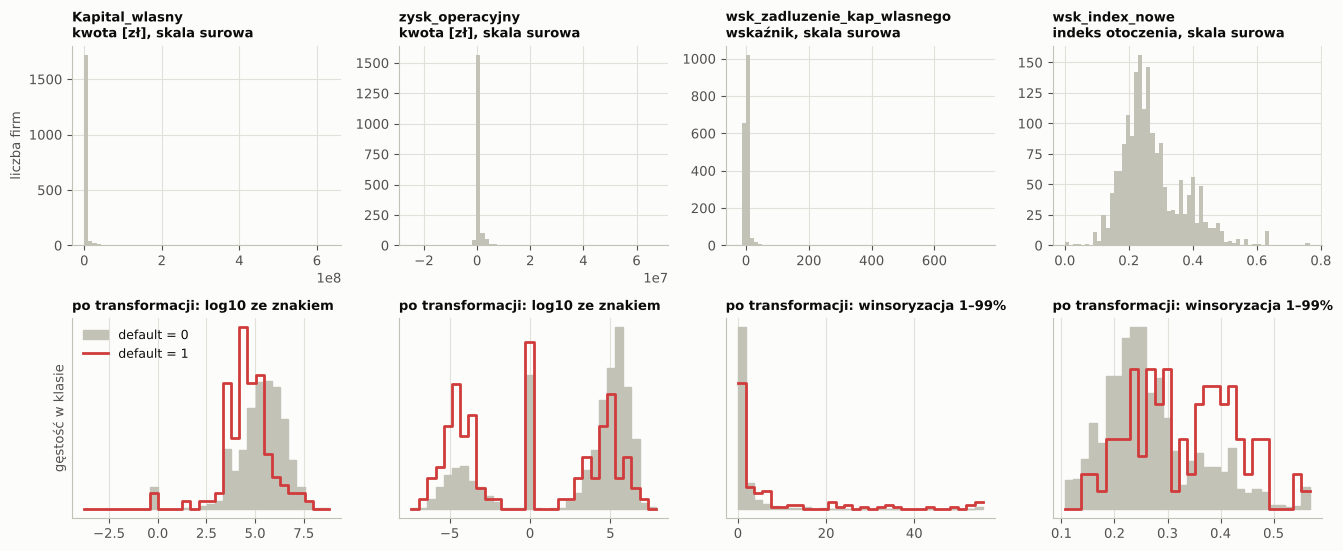

,count,min,1%,50%,99%,max,braki po czyszczeniu (%)
Kapital_wlasny,1800.0,-5.906630e+03,0.000,249230.865,3.759334e+07,6.313234e+08,0.000
zysk_operacyjny,1800.0,-2.484379e+07,-784477.248,36553.330,5.617994e+06,6.729318e+07,0.000
wsk_zadluzenie_kap_wlasnego,1754.0,-2.574900e+01,0.000,0.514,5.553700e+01,7.538160e+02,2.556
wsk_index_nowe,1800.0,0.000000e+00,0.106,0.254,5.680000e-01,7.650000e-01,0.000


In [23]:
def log_ze_znakiem(x):
    return np.sign(x) * np.log10(1 + np.abs(x))


y_np = y_train.to_numpy()
DR_TRAIN = float(y_np.mean())
panel = [("Kapital_wlasny", "kwota [zł]", "log"), ("zysk_operacyjny", "kwota [zł]", "log"),
         ("wsk_zadluzenie_kap_wlasnego", "wskaźnik", "winsor"), ("wsk_index_nowe", "indeks otoczenia", "winsor")]
fig, axes = plt.subplots(2, 4, figsize=(13.5, 5.6))
for j, (c, typ, transformacja) in enumerate(panel):
    x = X_eda[c].to_numpy(dtype=float)
    ok = ~np.isnan(x)
    axes[0, j].hist(x[ok], bins=60, color=K_TLO_SERII)
    axes[0, j].set_title(f"{c}\n{typ}, skala surowa", fontsize=9.5)
    if transformacja == "log":
        xt, opis = log_ze_znakiem(x), "log10 ze znakiem"
    else:
        xt, opis = np.clip(x, *np.nanquantile(x, [0.01, 0.99])), "winsoryzacja 1–99%"
    biny = np.linspace(np.nanmin(xt), np.nanmax(xt), 31)
    h0, _ = np.histogram(xt[ok & (y_np == 0)], bins=biny, density=True)
    h1, _ = np.histogram(xt[ok & (y_np == 1)], bins=biny, density=True)
    axes[1, j].fill_between(biny, np.r_[h0, h0[-1]], step="post", color=K_TLO_SERII, label="default = 0")
    axes[1, j].step(biny, np.r_[h1, h1[-1]], where="post", color=K_DEFAULT, lw=2, label="default = 1")
    axes[1, j].set_title(f"po transformacji: {opis}", fontsize=9.5)
    axes[1, j].set_yticks([])
axes[0, 0].set_ylabel("liczba firm")
axes[1, 0].set_ylabel("gęstość w klasie")
axes[1, 0].legend(loc="upper left")
pokaz("05_rozklady")

opis_rozkl = X_eda[[c for c, _, _ in panel]].describe(percentiles=[0.01, 0.5, 0.99]).T[["count", "min", "1%", "50%", "99%", "max"]].copy()
opis_rozkl["braki po czyszczeniu (%)"] = X_eda[[c for c, _, _ in panel]].isna().mean() * 100
display(opis_rozkl.round(3))

**Wnioski.**
* W skali surowej rozkłady są nieczytelne — praktycznie cała masa mieści się w jednym słupku, a oś rozciągają pojedyncze obserwacje. Po transformacji (logarytm ze znakiem dla kwot, winsoryzacja dla wskaźników) rozkłady stają się regularne i widać różnice między klasami: firmy z defaultem mają niższy kapitał własny i częściej stratę operacyjną, wyższą relację zobowiązań do kapitału własnego oraz wyższe wartości `wsk_index_nowe`.
* Różnice między klasami to **przesunięcia rozkładów, a nie rozdzielenie** — rozkłady silnie się nakładają. Pojedyncza cecha nie wystarczy; należy się spodziewać umiarkowanej mocy dyskryminacyjnej modeli.
* Transformacje pokazane na wykresie służą wyłącznie wizualizacji. W modelach ich rolę przejmują binning i winsoryzacja dopasowywane w pipeline (ETAP 5).

### 4.2. Zmienne kategoryczne a default

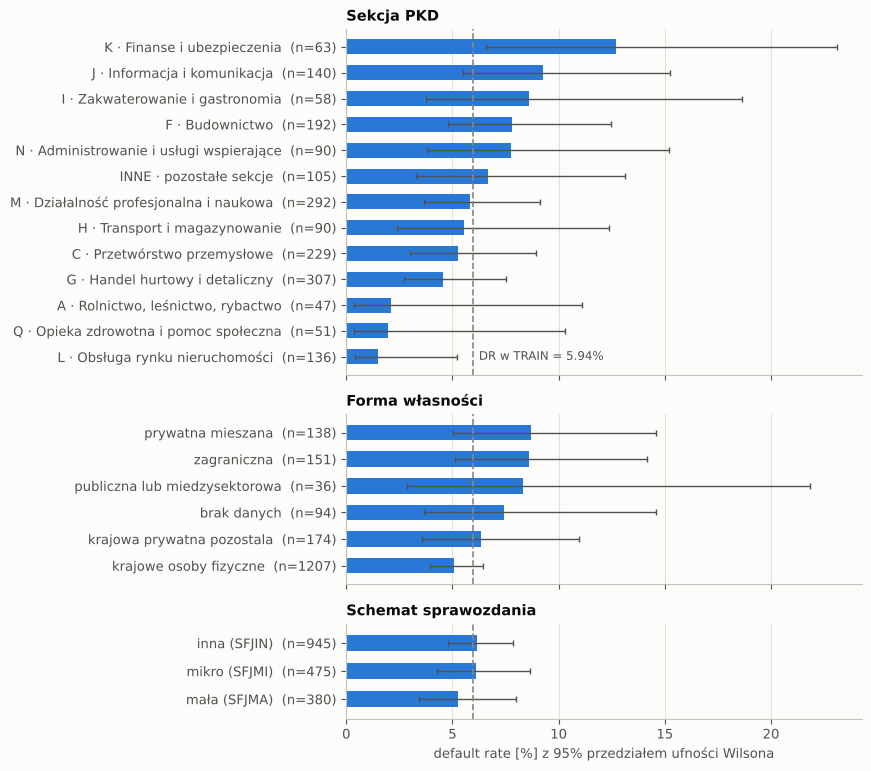

,liczba poziomów,chi2,p-value,V Craméra,min DR (%),max DR (%)
zmienna,,,,,,
pkd_sekcja,13,19.3,0.0806,0.104,1.5,12.7
forma_wlasnosci,6,6.3,0.2791,0.059,5.1,8.7
schemat_bilans,3,0.4,0.8185,0.015,5.3,6.1


---Sekcje PKD: liczebności i DR---


poziom,K,J,I,F,N,INNE,M,H,C,G,A,Q,L
n,63.00,140.00,58.00,192.00,90.00,105.00,292.00,90.00,229.00,307.00,47.00,51.00,136.00
defaulty,8.00,13.00,5.00,15.00,7.00,7.00,17.00,5.00,12.00,14.00,1.00,1.00,2.00
DR (%),12.70,9.29,8.62,7.81,7.78,6.67,5.82,5.56,5.24,4.56,2.13,1.96,1.47
CI dół (%),6.58,5.51,3.74,4.79,3.82,3.27,3.67,2.40,3.02,2.74,0.38,0.35,0.40
CI góra (%),23.11,15.24,18.64,12.49,15.19,13.13,9.12,12.35,8.93,7.51,11.11,10.30,5.20


In [24]:
def tabela_dr(kategoria, y):
    """Liczebność, liczba defaultów i DR z 95% przedziałem Wilsona dla każdego poziomu zmiennej kategorycznej."""
    t = pd.DataFrame({"poziom": np.asarray(kategoria), "y": np.asarray(y)}).groupby("poziom")["y"].agg(n="size", defaulty="sum")
    dol, gora = wilson(t["defaulty"], t["n"])
    t["DR (%)"], t["CI dół (%)"], t["CI góra (%)"] = t["defaulty"] / t["n"] * 100, dol * 100, gora * 100
    return t.sort_values("DR (%)")


NAZWY_SCHEMATOW = {"SFJIN": "inna (SFJIN)", "SFJMA": "mała (SFJMA)", "SFJMI": "mikro (SFJMI)"}


def etykieta_poziomu(cecha, poziom, n):
    if cecha == "pkd_sekcja":
        nazwa = f"{poziom} · {SEKCJA_OPIS[poziom]}" if poziom in SEKCJA_OPIS else "INNE · pozostałe sekcje"
    elif cecha == "forma_wlasnosci":
        nazwa = poziom.replace("_", " ")
    else:
        nazwa = NAZWY_SCHEMATOW.get(poziom, poziom)
    return f"{nazwa}  (n={n})"


KAT_PANEL = ["pkd_sekcja", "forma_wlasnosci", "schemat_bilans"]
TABELE_KAT = {c: tabela_dr(X_eda[c], y_train) for c in KAT_PANEL}
fig, axes = plt.subplots(3, 1, figsize=(8.8, 7.8), sharex=True, gridspec_kw={"height_ratios": [len(TABELE_KAT[c]) + 0.8 for c in KAT_PANEL]})
testy = []
for ax, c, tytul in zip(axes, KAT_PANEL, ["Sekcja PKD", "Forma własności", "Schemat sprawozdania"]):
    t = TABELE_KAT[c]
    poz = np.arange(len(t))
    ax.barh(poz, t["DR (%)"], height=0.58, color=K_SERIA)
    ax.errorbar(t["DR (%)"], poz, xerr=[t["DR (%)"] - t["CI dół (%)"], t["CI góra (%)"] - t["DR (%)"]], fmt="none", ecolor=TUSZ2, elinewidth=1, capsize=2)
    ax.axvline(DR_TRAIN * 100, color=SZARY, lw=1.2, ls="--")
    ax.set_yticks(poz, [etykieta_poziomu(c, p, n) for p, n in zip(t.index, t["n"])])
    ax.set_ylim(-0.7, len(t) - 0.3)
    ax.set_title(tytul)
    ax.grid(axis="y", visible=False)
    kontyngencja = pd.crosstab(X_eda[c], y_train)
    chi2, p, _, _ = chi2_contingency(kontyngencja)
    testy.append({"zmienna": c, "liczba poziomów": len(t), "chi2": round(float(chi2), 1), "p-value": round(float(p), 4),
                  "V Craméra": round(float(np.sqrt(chi2 / (kontyngencja.to_numpy().sum() * (min(kontyngencja.shape) - 1)))), 3),
                  "min DR (%)": round(float(t["DR (%)"].min()), 1), "max DR (%)": round(float(t["DR (%)"].max()), 1)})
axes[-1].set_xlabel("default rate [%] z 95% przedziałem ufności Wilsona")
axes[0].text(DR_TRAIN * 100 + 0.3, 0, f"DR w TRAIN = {DR_TRAIN:.2%}", fontsize=8.5, color=TUSZ2, va="center")
pokaz("06_kategorie_dr")
display(pd.DataFrame(testy).set_index("zmienna"))
print("---Sekcje PKD: liczebności i DR---")
display(TABELE_KAT["pkd_sekcja"].sort_values("DR (%)", ascending=False).round(2).T)

**Wnioski.**
* **Branża:** DR waha się od ok. 1,5–2% (obsługa nieruchomości, opieka zdrowotna, rolnictwo) do ok. 9–13% (informacja i komunikacja, finanse i ubezpieczenia). Liczbowo to duże różnice, ale w pojedynczej sekcji jest od jednego do kilkunastu defaultów, przedziały ufności są szerokie i test chi-kwadrat nie odrzuca braku zależności na poziomie 5% (p = 0,08; V Craméra = 0,10). Branżę zostawiamy jako kandydata — z grupowaniem rzadkich sekcji i wygładzaniem WoE — a o jej przydatności zdecyduje selekcja wewnątrz CV.
* **Forma własności:** spółki należące do krajowych osób fizycznych (2/3 próby) mają DR nieco poniżej średniej (5,1%), pozostałe grupy — powyżej (6–9%), ale różnice mieszczą się w granicach niepewności (p = 0,28).
* **Schemat sprawozdania** sam w sobie nie różnicuje ryzyka (DR 5,3–6,1%; p = 0,82). Jego znaczenie jest inne: decyduje o tym, które cechy finansowe są w ogóle dostępne (p. 3.2).

### 4.3. Siła jednowymiarowa cech liczbowych

Dla każdej cechy liczymy współczynnik Giniego (|2·AUC − 1|) — miarę niezależną od kierunku zależności, żeby nie pominąć cech „ochronnych” (im wyższa wartość, tym niższe ryzyko). Istotność oceniamy testem Manna–Whitneya z poprawką Benjaminiego–Hochberga, bo przy niemal 200 cechach i 107 defaultach część pozornych zależności to czysty przypadek.

Cech liczbowych: 193 | istotnych przy FDR 5%: 111 | Gini > 0,20: 78 | Gini > 0,30: 38
Pułap szumu (Gini cechy bez informacji, poziom 5% z poprawką na 193 testów): 0.210


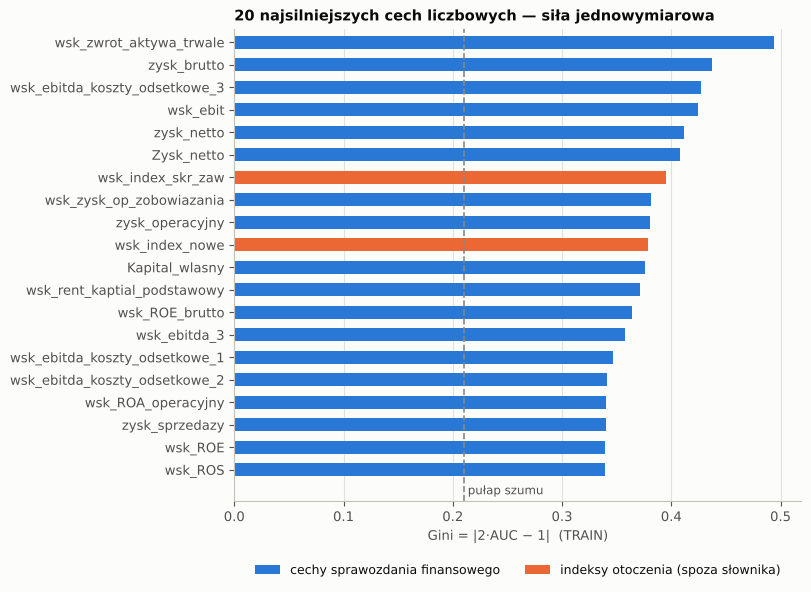

,Gini,ryzyko przy wzroście cechy,pokrycie (%),defaulty,q (BH),typ,formuła (z danych)
cecha,,,,,,,
wsk_zwrot_aktywa_trwale,0.494,maleje,41.9,35,0.00001,wskaźnik (iloraz),zysk_operacyjny / Srodki_trwale
zysk_brutto,0.437,maleje,74.0,79,0.00000,pozycja kwotowa [zł],
wsk_ebitda_koszty_odsetkowe_3,0.428,maleje,40.4,40,0.00003,wskaźnik (iloraz),wsk_ebitda_3 / koszty_odsetki
wsk_ebit,0.424,maleje,74.0,79,0.00000,pozycja kwotowa [zł],
zysk_netto,0.411,maleje,74.0,79,0.00000,pozycja kwotowa [zł],
Zysk_netto,0.408,maleje,73.6,78,0.00000,pozycja kwotowa [zł],
wsk_index_skr_zaw,0.395,rośnie,100.0,107,0.00000,indeks otoczenia,
wsk_zysk_op_zobowiazania,0.381,maleje,66.6,66,0.00000,wskaźnik (iloraz),zysk_operacyjny / wsk_Zobowiazania_krotkoterminowe
zysk_operacyjny,0.380,maleje,100.0,107,0.00000,pozycja kwotowa [zł],


In [25]:
def bh(p):
    """Poprawka Benjaminiego-Hochberga (kontrola odsetka fałszywych odkryć, FDR)."""
    p = np.asarray(p, dtype=float)
    kolej = np.argsort(p)
    q = np.minimum.accumulate((p[kolej] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    out = np.empty(len(p))
    out[kolej] = np.minimum(q, 1.0)
    return out


wiersze = []
for c in NUM_EDA:
    x = X_eda[c].to_numpy(dtype=float)
    ok = ~np.isnan(x)
    if y_np[ok].min() == y_np[ok].max():
        continue
    auc = roc_auc_score(y_np[ok], x[ok])
    wiersze.append({"cecha": c, "Gini": abs(2 * auc - 1), "ryzyko przy wzroście cechy": "rośnie" if auc > 0.5 else "maleje",
                    "pokrycie (%)": ok.mean() * 100, "defaulty": int(y_np[ok].sum()),
                    "p": mannwhitneyu(x[ok & (y_np == 1)], x[ok & (y_np == 0)], alternative="two-sided").pvalue})
SILA = pd.DataFrame(wiersze).set_index("cecha")
SILA["q (BH)"] = bh(SILA["p"])
SILA = SILA.sort_values("Gini", ascending=False)

n1, n0 = int(y_np.sum()), int((1 - y_np).sum())
se0 = np.sqrt((n1 + n0 + 1) / (12 * n1 * n0))                         # błąd standardowy AUC, gdy cecha nie niesie informacji
pulap_szumu = 2 * norm.ppf(1 - 0.05 / (2 * len(SILA))) * se0          # największy Gini, jakiego można oczekiwać od samego szumu
print(f"Cech liczbowych: {len(SILA)} | istotnych przy FDR 5%: {int((SILA['q (BH)'] < 0.05).sum())} | Gini > 0,20: {int((SILA['Gini'] > 0.20).sum())}"
      f" | Gini > 0,30: {int((SILA['Gini'] > 0.30).sum())}")
print(f"Pułap szumu (Gini cechy bez informacji, poziom 5% z poprawką na {len(SILA)} testów): {pulap_szumu:.3f}")

top = SILA.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.2, 6.0))
kolory = [K_AKCENT if c in INDEKSY else K_SERIA for c in top.index]
ax.barh(top.index, top["Gini"], height=0.58, color=kolory)
ax.axvline(pulap_szumu, color=SZARY, lw=1.2, ls="--")
ax.text(pulap_szumu, -0.95, " pułap szumu", fontsize=8.5, color=TUSZ2, va="center")
ax.barh([np.nan], [np.nan], color=K_SERIA, label="cechy sprawozdania finansowego")
ax.barh([np.nan], [np.nan], color=K_AKCENT, label="indeksy otoczenia (spoza słownika)")
ax.set(xlabel="Gini = |2·AUC − 1|  (TRAIN)", title="20 najsilniejszych cech liczbowych — siła jednowymiarowa", ylim=(-1.4, len(top) - 0.4))
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2)
pokaz("07_sila_jednowymiarowa")

tabela = SILA.head(15).join(META[["typ", "formuła (z danych)"]])
display(tabela[["Gini", "ryzyko przy wzroście cechy", "pokrycie (%)", "defaulty", "q (BH)", "typ", "formuła (z danych)"]].round({"Gini": 3, "pokrycie (%)": 1, "q (BH)": 5}))

**Wnioski.**
* Sygnał w danych jest wyraźny, ale umiarkowany: najsilniejsze pojedyncze cechy mają Gini 0,35–0,50 (AUC 0,68–0,75), a 111 ze 193 cech liczbowych jest istotnych statystycznie po poprawce na wielokrotne testowanie. Dla orientacji: przy 107 defaultach żadna ze 193 cech czysto losowych nie powinna przekroczyć Gini ok. 0,21 („pułap szumu”) — dwadzieścia najsilniejszych cech leży wyraźnie powyżej.
* Wśród najsilniejszych dominują trzy grupy: **(1) wynik finansowy i rentowność** (zysk brutto, netto i operacyjny, EBIT, EBITDA, ROE, pokrycie odsetek — wyższy wynik, niższe ryzyko), **(2) kapitał własny** (wyższy kapitał — niższe ryzyko) oraz **(3) indeksy otoczenia** `wsk_index_skr_zaw` i `wsk_index_nowe` (wyższy indeks — wyższe ryzyko).
* Kierunki zależności są zgodne z intuicją ekonomiczną, co jest dobrą wiadomością dla modelu interpretowalnego: monotoniczny binning będzie miał uzasadnienie merytoryczne.
* Gini liczymy na obserwacjach, dla których cecha jest określona (kolumna „pokrycie”). Cechy o niskim pokryciu — np. `wsk_zwrot_aktywa_trwale` (42%: tylko firmy posiadające środki trwałe) — różnicują ryzyko jedynie w części portfela; pełniejszy obraz daje IV liczone razem z koszykiem braków (ETAP 5).
* Pozycje kwotowe (`zysk_brutto`, `Kapital_wlasny`) są silne po części dlatego, że niosą **efekt skali** — większe firmy rzadziej upadają. To realny czynnik ryzyka, ale warto o nim pamiętać przy interpretacji: model będzie po części „modelem wielkości firmy”.
* Dwie z dziesięciu najsilniejszych cech to nieopisane w słowniku indeksy otoczenia. Nie są podejrzanie silne (daleko im do idealnej separacji), ale ich wpływ na model będzie duży — patrz p. 6.2.

### 4.4. Korelacje i redundancja cech

Par cech: 18528 | z |rho| >= 0,80: 490 | z |rho| >= 0,95: 108
Klastrów cech (średnie |rho| >= 0,80): 90 na 193 cech | cech w klastrach wieloelementowych: 136 | największy klaster: 12 cech


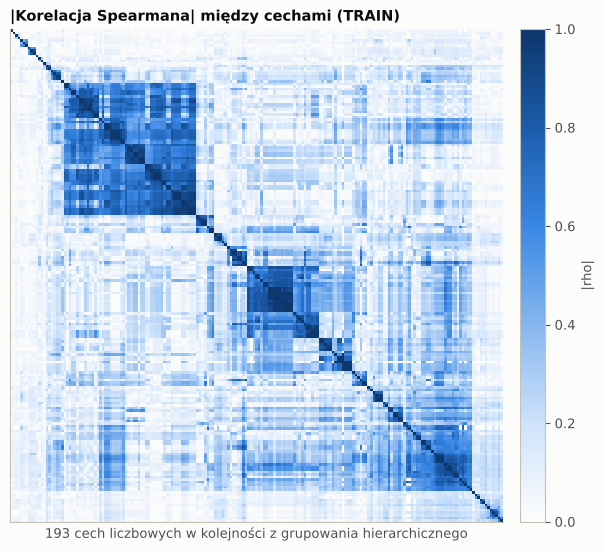

---Największe klastry cech skorelowanych---


,liczba cech,reprezentant (najwyższy Gini),Gini,pozostałe (przykłady)
0,12,wsk_struktury_kapitalu,0.263,"wsk_kapital_do_aktywa, wsk_mnoznik_kap_wl, wsk_ogolnego_zadluzenia_1, wsk_ogolnego_zad..."
1,12,wsk_rent_kaptial_podstawowy,0.372,"wsk_ROA, wsk_s_ROA, wsk_ROE, wsk_s_ROE"
2,9,wsk_zysk_op_zobowiazania,0.381,"wsk_stopa_marzy_brutto, wsk_rent_operacyjna, wsk_rent_operacyjna_aktywow, wsk_marza_eb..."
3,8,zysk_brutto,0.437,"Zysk_netto, zysk_operacyjny, zysk_netto, wsk_ebit"
4,8,wsk_ebitda_koszty_odsetkowe_3,0.428,"wsk_pokrycie_wyd_fin_gotowkowe_1, wsk_pokrycia_odsetek_zyskiem, wsk_ebitda_koszty_odse..."
5,6,Kapital_wlasny,0.376,"Aktywa, Aktywa_obrotowe, Zobowiazania_rezerwy, Zobowiazania_krotkoterminowe"
6,6,wsk_zob_oprocentowanych_aktywa_rzeczowe,0.054,"Kredyty_pozyczki_dlugie, Kredyty_pozyczki, wsk_ogolnego_zadluzenia_pozyczki, wsk_zadlu..."
7,6,wsk_ROS,0.339,"wsk_marza_brutto_1, wsk_marza_brutto_2, wsk_marza_ebitda_1, wsk_marza_ebitda_2"


In [26]:
rho = X_eda[NUM_EDA].corr(method="spearman", min_periods=100).abs().fillna(0.0).to_numpy()
rho = (rho + rho.T) / 2
np.fill_diagonal(rho, 1.0)
drzewo = hierarchy.linkage(squareform(1 - rho, checks=False), method="average")
kolej = hierarchy.leaves_list(drzewo)
KLASTER = pd.Series(hierarchy.fcluster(drzewo, t=0.20, criterion="distance"), index=NUM_EDA)   # średnie |rho| w klastrze >= 0,8

gorny = rho[np.triu_indices(len(NUM_EDA), k=1)]
rozmiary = KLASTER.value_counts()
print(f"Par cech: {len(gorny)} | z |rho| >= 0,80: {int((gorny >= 0.80).sum())} | z |rho| >= 0,95: {int((gorny >= 0.95).sum())}")
print(f"Klastrów cech (średnie |rho| >= 0,80): {len(rozmiary)} na {len(NUM_EDA)} cech | cech w klastrach wieloelementowych: {int(rozmiary[rozmiary > 1].sum())}"
      f" | największy klaster: {int(rozmiary.max())} cech")

fig, ax = plt.subplots(figsize=(6.6, 5.6))
im = ax.imshow(rho[np.ix_(kolej, kolej)], cmap=CMAP_SEQ, vmin=0, vmax=1, interpolation="nearest")
ax.set(xticks=[], yticks=[], xlabel=f"{len(NUM_EDA)} cech liczbowych w kolejności z grupowania hierarchicznego",
       title="|Korelacja Spearmana| między cechami (TRAIN)")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="|rho|")
pokaz("08_korelacje")

wiersze = []
for k in rozmiary.index[:8]:
    czlonkowie = KLASTER.index[KLASTER == k]
    reprezentant = SILA.loc[SILA.index.intersection(czlonkowie), "Gini"].idxmax()
    wiersze.append({"liczba cech": len(czlonkowie), "reprezentant (najwyższy Gini)": reprezentant, "Gini": round(SILA.at[reprezentant, "Gini"], 3),
                    "pozostałe (przykłady)": ", ".join([c for c in czlonkowie if c != reprezentant][:4])})
print("---Największe klastry cech skorelowanych---")
display(pd.DataFrame(wiersze))

**Wnioski.**
* Cechy są silnie redundantne: na mapie widać wyraźne bloki, 490 par cech ma |ρ| ≥ 0,8, a 108 par — co najmniej 0,95. To naturalne: wskaźniki są liczone z tych samych kilkunastu pozycji sprawozdania, często w kilku wariantach (`…_1`, `…_2`, `…_3`).
* Efektywna liczba „tematów” jest znacznie mniejsza niż liczba kolumn: 193 cechy układają się w 90 klastrów (średnia |ρ| w klastrze ≥ 0,8), a największe z nich — struktura kapitału i zadłużenie, rentowność, wynik finansowy, pokrycie odsetek — liczą po 8–12 cech.
* **Konsekwencje:** (1) do modelu interpretowalnego wybieramy po jednym reprezentancie z grupy cech skorelowanych — inaczej współczynniki regresji byłyby niestabilne i trudne do interpretacji; (2) w modelu black-box ważność cech (np. SHAP) będzie się „rozkładać” między cechy z tego samego klastra, co trzeba uwzględnić przy ocenie stabilności wyjaśnień — porównywać warto wkład całych klastrów, a nie pojedynczych wariantów wskaźnika.

### 4.5. Kształt zależności: default rate w kwintylach cechy

Dla ośmiu najsilniejszych cech — po jednej z każdego klastra korelacji — pokazujemy DR w kwintylach wartości (z 95% przedziałem Wilsona) oraz osobno w grupie braków, czyli wartości specjalnych z p. 3.2–3.3.

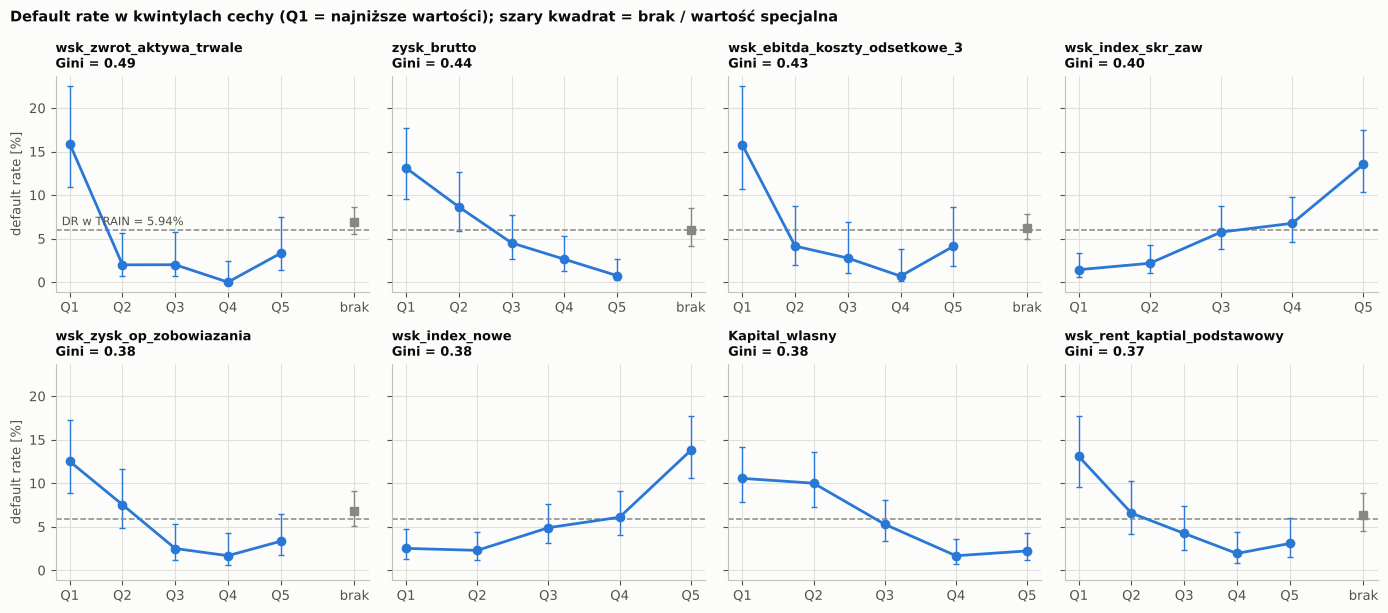

---Granice kwintyli i liczebności (pierwsze trzy cechy)---


przedział     n  defaulty  DR (%)
cecha                         grupa                                                  
wsk_zwrot_aktywa_trwale       Q1             [-inf, -0.03032)   151      24.0   15.89
                              Q2          [-0.03032, 0.09382)   151       3.0    1.99
                              Q3            [0.09382, 0.6229)   150       3.0    2.00
                              Q4              [0.6229, 3.095)   151       0.0    0.00
                              Q5                 [3.095, inf)   151       5.0    3.31
                              brak   wartość specjalna / brak  1046      72.0    6.88
zysk_brutto                   Q1                [-inf, -5013)   267      35.0   13.11
                              Q2                [-5013, 4078)   266      23.0    8.65
                              Q3            [4078, 6.667e+04)   266      12.0    4.51
                              Q4        [6.667e+04, 3.56e+05)   266       7.0    2.63
                              Q5              [3.56e+05, inf)   267       2.0    0.75
                              brak   wartość specjalna / brak   468      28.0    5.98
wsk_ebitda_koszty_odsetkowe_3 Q1              [-inf, -0.0792)   146      23.0   15.75
                              Q2             [-0.0792, 7.694)   145       6.0    4.14
                              Q3                  [7.694, 32)   145       4.0    2.76
                              Q4                  [32, 423.5)   145       1.0    0.69
                              Q5                 [423.5, inf)   146       6.0    4.11
                              brak   wartość specjalna / brak  1073      67.0    6.24

In [27]:
def profil_dr(x, y, n_bins=5):
    """DR w kwantylowych przedziałach cechy; braki danych jako osobna grupa."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    ok = ~np.isnan(x)
    krawedzie = np.unique(np.quantile(x[ok], np.linspace(0, 1, n_bins + 1)[1:-1]))
    nr = np.searchsorted(krawedzie, x[ok], side="right")
    n, d = np.bincount(nr, minlength=len(krawedzie) + 1), np.bincount(nr, weights=y[ok], minlength=len(krawedzie) + 1)
    granice = np.r_[-np.inf, krawedzie, np.inf]
    t = pd.DataFrame({"przedział": [f"[{granice[i]:.4g}, {granice[i + 1]:.4g})" for i in range(len(n))], "n": n, "defaulty": d})
    t = t[t["n"] > 0].reset_index(drop=True)
    t.insert(0, "grupa", [f"Q{i + 1}" for i in range(len(t))])
    if (~ok).sum() > 0:
        t.loc[len(t)] = ["brak", "wartość specjalna / brak", int((~ok).sum()), float(y[~ok].sum())]
    dol, gora = wilson(t["defaulty"], t["n"])
    t["DR (%)"], t["CI dół (%)"], t["CI góra (%)"] = t["defaulty"] / t["n"] * 100, dol * 100, gora * 100
    return t


reprezentanci = SILA.assign(klaster=KLASTER).groupby("klaster")["Gini"].idxmax()
PROFILOWANE = SILA.loc[reprezentanci].sort_values("Gini", ascending=False).head(8).index.tolist()

fig, axes = plt.subplots(2, 4, figsize=(14, 6.2), sharey=True)
zestawienie = []
for ax, c in zip(axes.ravel(), PROFILOWANE):
    t = profil_dr(X_eda[c], y_train)
    kw = t[t["grupa"] != "brak"]
    ax.errorbar(np.arange(len(kw)), kw["DR (%)"], yerr=[kw["DR (%)"] - kw["CI dół (%)"], kw["CI góra (%)"] - kw["DR (%)"]],
                color=K_SERIA, marker="o", lw=2, elinewidth=1, capsize=2.5, ecolor=K_SERIA)
    if (t["grupa"] == "brak").any():
        b = t[t["grupa"] == "brak"].iloc[0]
        ax.errorbar([len(kw) + 0.4], [b["DR (%)"]], yerr=[[b["DR (%)"] - b["CI dół (%)"]], [b["CI góra (%)"] - b["DR (%)"]]],
                    color=SZARY, marker="s", elinewidth=1, capsize=2.5)
    ax.axhline(DR_TRAIN * 100, color=SZARY, lw=1.1, ls="--")
    ax.set_xticks(list(range(len(kw))) + ([len(kw) + 0.4] if (t["grupa"] == "brak").any() else []), t["grupa"].tolist())
    ax.set_title(f"{c}\nGini = {SILA.at[c, 'Gini']:.2f}", fontsize=9.3)
    zestawienie.append(t.assign(cecha=c))
for ax in axes[:, 0]:
    ax.set_ylabel("default rate [%]")
axes[0, 0].text(0.02, DR_TRAIN * 100 + 0.6, f"DR w TRAIN = {DR_TRAIN:.2%}", transform=axes[0, 0].get_yaxis_transform(), fontsize=8.3, color=TUSZ2)
fig.suptitle("Default rate w kwintylach cechy (Q1 = najniższe wartości); szary kwadrat = brak / wartość specjalna", x=0.01, ha="left", fontsize=10.5, fontweight="bold")
pokaz("09_profile_dr")

print("---Granice kwintyli i liczebności (pierwsze trzy cechy)---")
display(pd.concat(zestawienie[:3]).set_index(["cecha", "grupa"])[["przedział", "n", "defaulty", "DR (%)"]].round(2))

**Wnioski.**
* Zależności są w przeważającej mierze **monotoniczne**: DR spada wraz ze wzrostem wyniku finansowego i kapitału własnego, a rośnie wraz z indeksami otoczenia. Rozpiętość jest duża — np. dla `zysk_brutto` od 13,1% w najniższym kwintylu do 0,8% w najwyższym, a dla indeksów otoczenia od ok. 1,5–2,5% do ok. 13,5%.
* Zależności są zarazem **nieliniowe**: ryzyko skupia się w skrajnym kwintylu (strata, najniższy kapitał), a dalej zmienia się słabo. Model liniowy na surowych wartościach źle by to opisał — stąd binning i WoE w modelu interpretowalnym.
* W kilku wskaźnikach-ilorazach widać lekkie odbicie DR w najwyższym kwintylu. Bardzo wysokie wartości ilorazu to często skutek małego mianownika, a nie znakomitej kondycji firmy; wymuszenie monotoniczności połączy te koszyki, zamiast dopasowywać się do szumu.
* Grupa braków (szary kwadrat) ma DR zbliżony do średniej: brak informacji o wyniku finansowym jednostki mikro albo nieokreślony wskaźnik nie jest sam w sobie ani dobrą, ani złą wiadomością.

### 4.6. Czy brak wartości niesie informację o ryzyku?

Po rekodowaniu wartości specjalnych braki nie są losowe — oznaczają konkretną sytuację firmy (pozycja nieraportowana albo wskaźnik nieokreślony). Sprawdzamy, czy sama obecność braku różnicuje ryzyko. Cechy o identycznym wzorcu braków grupujemy, żeby tej samej informacji nie liczyć wielokrotnie.

In [28]:
wzorce = {}
for c in NUM_EDA:
    m = X_eda[c].isna().to_numpy()
    if 90 <= m.sum() <= len(m) - 90:
        wzorce.setdefault(m.tobytes(), []).append(c)
wiersze = []
for klucz, lista in wzorce.items():
    m = np.frombuffer(klucz, dtype=bool)
    tab = np.array([[y_np[m].sum(), (1 - y_np[m]).sum()], [y_np[~m].sum(), (1 - y_np[~m]).sum()]])
    wiersze.append({"przykładowa cecha": lista[0], "cech o tym wzorcu": len(lista), "braki (%)": m.mean() * 100,
                    "DR gdy brak (%)": y_np[m].mean() * 100, "DR gdy jest wartość (%)": y_np[~m].mean() * 100, "p (chi2)": chi2_contingency(tab)[1]})
BRAKI_DR = pd.DataFrame(wiersze)
BRAKI_DR["różnica (p.p.)"] = BRAKI_DR["DR gdy brak (%)"] - BRAKI_DR["DR gdy jest wartość (%)"]
BRAKI_DR["q (BH)"] = bh(BRAKI_DR["p (chi2)"])
print(f"Różnych wzorców braków (>= 90 obserwacji w każdej grupie): {len(BRAKI_DR)} | istotnych przy FDR 5%: {int((BRAKI_DR['q (BH)'] < 0.05).sum())}")
display(BRAKI_DR.reindex(BRAKI_DR["różnica (p.p.)"].abs().sort_values(ascending=False).index).head(8)
        .drop(columns="p (chi2)").round({"braki (%)": 1, "DR gdy brak (%)": 2, "DR gdy jest wartość (%)": 2, "różnica (p.p.)": 2, "q (BH)": 4}).reset_index(drop=True))

Różnych wzorców braków (>= 90 obserwacji w każdej grupie): 38 | istotnych przy FDR 5%: 0


,przykładowa cecha,cech o tym wzorcu,braki (%),DR gdy brak (%),DR gdy jest wartość (%),różnica (p.p.),q (BH)
0,wsk_stopa_marzy_brutto,4,22.7,8.33,5.24,3.09,0.7558
1,wsk_rotacja_rz_aktywow_trwalych,1,56.4,6.99,4.59,2.40,0.7558
2,wsk_zwrot_aktywa_trwale,1,58.1,6.88,4.64,2.24,0.7558
3,wsk_koszty_fin_przychody,1,39.3,7.07,5.22,1.86,0.9308
4,wsk_rotacja_wartosci_niewaterialnych,1,89.7,6.13,4.32,1.81,1.0000
5,wsk_koszty_odsetki_przychody,1,39.6,7.01,5.24,1.77,0.9308
6,wsk_udzial_zob_biez_sprzedaz_1,1,39.6,7.01,5.24,1.77,0.9308
7,wsk_marza_brutto_2,3,39.2,6.95,5.30,1.65,0.9677


**Wnioski.** Wśród 38 różnych wzorców braków **żaden nie różnicuje ryzyka w sposób istotny statystycznie** (po poprawce na wielokrotne testowanie). Największą różnicę widać dla firm bez przychodów ze sprzedaży (nieokreślone marże: DR 8,3% wobec 5,2%), ale i ona mieści się w granicach przypadku. Brak wartości jest więc informacją o *sytuacji* firmy, a nie sygnałem ostrzegawczym: w modelu interpretowalnym dostaje osobny koszyk o WoE bliskim zera (firma nie jest ani karana, ani nagradzana za to, że wskaźnika nie da się policzyć), a w modelu black-box — brak natywny lub flagę braku.

### 4.7. Wnioski z EDA — implikacje dla przygotowania cech

| Obserwacja | Implikacja |
|---|---|
| Rozkłady skrajnie skośne, wartości odstające są regułą | binning (model interpretowalny), winsoryzacja 1–99% (cechy surowe); żadnej standaryzacji bez wcześniejszego cappingu |
| Zależności z targetem monotoniczne, ale nieliniowe | **binning monotoniczny + WoE** dobrze oddaje kształt zależności i zachowuje interpretowalność |
| Braki to wartości specjalne (pozycja nieraportowana, wskaźnik nieokreślony) o DR zbliżonym do średniej | brak = osobny koszyk WoE; w modelu black-box brak natywny lub flaga braku — nigdy „ciche” wstawienie zera |
| Silna redundancja cech (90 klastrów na 193 cechy) | selekcja: najwyższe IV w grupie cech skorelowanych; ocena stabilności wyjaśnień na poziomie klastrów |
| 107 defaultów w TRAIN | mało parametrów: do 5 koszyków na cechę, kilkanaście cech w modelu logitowym; wygładzanie WoE; wszystko oceniane w CV |
| Zmienne kategoryczne słabo różnicują ryzyko | zostają jako kandydaci (rzadkie poziomy zgrupowane), ale nie oczekujemy po nich dużego wkładu |
| Dwie z najsilniejszych cech to nieopisane indeksy otoczenia | cechy zostają jako kandydaci, ale z analizą wrażliwości (p. 6.2) |
| Jednostki mikro mają znacznie mniej informacji finansowej | stratyfikacja po schemacie (zrobione); wyniki modeli warto raportować także w podziale na schematy |

## ETAP 5. Przygotowanie cech pod modele

Oba modele dostają cechy z tego samego, wspólnego początku (kategorie → wartości specjalne → czyszczenie), a różnią się ostatnim krokiem: model interpretowalny pracuje na cechach **WoE po monotonicznym binningu**, model black-box — na cechach **surowych po cappingu**.

### 5.1. Polityka przygotowania cech

| Element | Model interpretowalny (regresja logistyczna / scorecard) | Model black-box |
|---|---|---|
| Zmienne kategoryczne | sekcja PKD, grupa formy własności, schematy; rzadkie poziomy → `INNE`; kodowanie **WoE** | te same kategorie; kodowanie **one-hot** |
| Wartości specjalne (inf, zera strukturalne, zerowy mianownik) | brak danych → **osobny koszyk** z własnym WoE | brak danych → obsługa natywna (modele drzewiaste) albo mediana + flaga braku |
| Obserwacje odstające (capping/outlier policy) | binning: skrajne wartości trafiają do skrajnych, otwartych koszyków | **winsoryzacja** do percentyli 1–99 ze zbioru uczącego |
| Nieliniowość | **binning monotoniczny**: do 5 koszyków, każdy ≥ 5% obserwacji, monotoniczne log-szanse | model uczy się jej sam |
| Skala cech | WoE sprowadza wszystkie cechy do wspólnej skali (log-szans) — standaryzacja zbędna | modele drzewiaste: zbędna; SVM / sieć: logarytm ze znakiem + **standaryzacja** po cappingu |
| Selekcja cech | IV ≥ próg, eliminacja cech skorelowanych (zostaje cecha o wyższym IV), limit liczby cech | brak twardej selekcji na tym etapie (usuwane tylko duplikaty, cechy quasi-stałe i z > 90% braków) |
| Gdzie dopasowywane | wyłącznie zbiór uczący / część ucząca folda — każdy element jest krokiem `Pipeline` | jw. |

### 5.2. Binning monotoniczny i WoE

Konwencja: `WoE = ln(udział złych w koszyku / udział dobrych w koszyku)`, więc **WoE > 0 oznacza ryzyko wyższe od przeciętnego**, a współczynniki regresji logistycznej przy cechach WoE powinny być dodatnie. Algorytm binningu cechy liczbowej:
1. wstępny podział na przedziały kwantylowe;
2. łączenie przedziałów mniejszych niż 5% próby;
3. łączenie sąsiednich przedziałów łamiących monotoniczność log-szans (sprawdzamy oba kierunki, wybieramy ten o wyższym IV);
4. redukcja do zadanej liczby koszyków przez łączenie sąsiadów o najbardziej zbliżonym ryzyku;
5. braki danych tworzą osobny koszyk (jeżeli jest ich mniej niż 5% próby, dostają neutralne WoE = 0 — nie estymujemy ryzyka z garstki obserwacji).

In [29]:
def _woe_iv(bad, good, s=0.5):
    """WoE i IV dla wektorów liczby złych i dobrych w koszykach; `s` - wygładzanie addytywne (chroni przed ln(0), tłumi małe koszyki)."""
    bad, good = np.asarray(bad, dtype=float), np.asarray(good, dtype=float)
    pb = (bad + s) / (bad.sum() + s * len(bad))
    pg = (good + s) / (good.sum() + s * len(good))
    woe = np.log(pb / pg)
    return woe, float(((pb - pg) * woe).sum())


def _log_szanse(tot, bad, s=0.5):
    tot, bad = np.asarray(tot, dtype=float), np.asarray(bad, dtype=float)
    return np.log((bad + s) / (tot - bad + s))


def _polacz(krawedzie, tot, bad, i):
    """Łączy koszyk i z koszykiem i+1."""
    krawedzie.pop(i)
    tot[i] += tot.pop(i + 1)
    bad[i] += bad.pop(i + 1)


def _wymus_monotonicznosc(krawedzie, tot, bad, kierunek, s):
    krawedzie, tot, bad = list(krawedzie), list(tot), list(bad)
    while len(tot) > 1:
        roznice = np.diff(_log_szanse(tot, bad, s))
        naruszenia = np.flatnonzero(roznice < 0) if kierunek == "rosnący" else np.flatnonzero(roznice > 0)
        if len(naruszenia) == 0:
            break
        _polacz(krawedzie, tot, bad, int(naruszenia[0]))
    return krawedzie, tot, bad


def fit_numeric_bins(x, y, max_bins=5, min_bin_frac=0.05, monotonic=True, n_init=20, smoothing=0.5):
    """Monotoniczny binning cechy liczbowej + WoE (braki danych = osobny koszyk). Zwraca słownik z opisem koszyków."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    jest = ~np.isnan(x)
    xv, yv = x[jest], y[jest]
    n_nan, bad_nan = int((~jest).sum()), float(y[~jest].sum())
    min_n = max(int(np.ceil(min_bin_frac * len(x))), 1)

    krawedzie = []
    if len(xv) and xv.min() < xv.max():                                                    # 1) przedziały kwantylowe
        krawedzie = [k for k in np.unique(np.quantile(xv, np.linspace(0, 1, n_init + 1)[1:-1])).tolist() if k > xv.min()]
    nr = np.searchsorted(krawedzie, xv, side="right")
    tot = np.bincount(nr, minlength=len(krawedzie) + 1).astype(float).tolist()
    bad = np.bincount(nr, weights=yv, minlength=len(krawedzie) + 1).tolist()

    while len(tot) > 1 and min(tot) < min_n:                                               # 2) minimalna liczebność
        i = int(np.argmin(tot))
        lo = _log_szanse(tot, bad, smoothing)
        sasiad = min([k for k in (i - 1, i + 1) if 0 <= k < len(tot)], key=lambda k: abs(lo[k] - lo[i]))
        _polacz(krawedzie, tot, bad, min(i, sasiad))

    kierunek = "brak"
    if monotonic and len(tot) > 1:                                                         # 3) monotoniczność
        warianty = []
        for k in ("rosnący", "malejący"):
            kr, t, b = _wymus_monotonicznosc(krawedzie, tot, bad, k, smoothing)
            warianty.append((_woe_iv(b, np.array(t) - np.array(b), smoothing)[1], k, kr, t, b))
        _, kierunek, krawedzie, tot, bad = max(warianty, key=lambda w: w[0])
        if len(tot) == 1:
            kierunek = "brak"

    while len(tot) > max_bins:                                                             # 4) limit liczby koszyków
        _polacz(krawedzie, tot, bad, int(np.argmin(np.abs(np.diff(_log_szanse(tot, bad, smoothing))))))

    osobny_brak = n_nan >= min_n                                                           # 5) koszyk braków
    tot_w, bad_w = tot + ([n_nan] if osobny_brak else []), bad + ([bad_nan] if osobny_brak else [])
    woe, iv = _woe_iv(bad_w, np.array(tot_w) - np.array(bad_w), smoothing)
    return {"kind": "num", "edges": np.array(krawedzie, dtype=float), "woe": woe[:len(tot)], "nan_woe": float(woe[-1]) if osobny_brak else 0.0,
            "nan_bin": osobny_brak, "iv": iv, "direction": kierunek, "counts": np.array(tot), "bads": np.array(bad), "n_nan": n_nan, "bad_nan": bad_nan}


def fit_categorical_woe(x, y, smoothing=0.5):
    """WoE dla zmiennej kategorycznej: każdy poziom to osobny koszyk (rzadkie poziomy zgrupował już CategoryPreparer)."""
    g = pd.DataFrame({"x": np.asarray(x).astype(str), "y": np.asarray(y, dtype=float)}).groupby("x")["y"].agg(["sum", "count"])
    woe, iv = _woe_iv(g["sum"].to_numpy(), (g["count"] - g["sum"]).to_numpy(), smoothing)
    return {"kind": "cat", "levels": g.index.tolist(), "woe": woe, "nan_woe": 0.0, "nan_bin": False, "iv": iv, "direction": "n/d",
            "counts": g["count"].to_numpy(dtype=float), "bads": g["sum"].to_numpy(dtype=float), "n_nan": 0, "bad_nan": 0.0}


def apply_bins(b, x):
    """Zamienia wartości cechy na WoE według zapamiętanych koszyków; poziom nieznany lub brak bez własnego koszyka -> WoE = 0."""
    if b["kind"] == "cat":
        mapa = dict(zip(b["levels"], b["woe"]))
        return np.array([mapa.get(v, 0.0) for v in np.asarray(x).astype(str)], dtype=float)
    v = np.asarray(x, dtype=float)
    brak = np.isnan(v)
    return np.where(brak, b["nan_woe"], b["woe"][np.searchsorted(b["edges"], np.where(brak, 0.0, v), side="right")])


class WoEEncoder(TransformerMixin, BaseEstimator):
    """Binning + WoE + selekcja cech. Wszystko wyznaczane w `fit` (wymaga y), więc krok musi być częścią Pipeline.

    Selekcja: (1) IV >= `iv_min`, (2) cechy w kolejności malejącego IV; cecha odpada, jeśli jej WoE koreluje z już wybraną
    cechą na poziomie |r| >= `corr_max`, (3) opcjonalny limit `max_features`.
    """

    def __init__(self, max_bins=5, min_bin_frac=0.05, monotonic=True, n_init=20, smoothing=0.5, iv_min=0.10, corr_max=0.70, max_features=None):
        self.max_bins = max_bins
        self.min_bin_frac = min_bin_frac
        self.monotonic = monotonic
        self.n_init = n_init
        self.smoothing = smoothing
        self.iv_min = iv_min
        self.corr_max = corr_max
        self.max_features = max_features

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.bins_ = {}
        for c in X.columns:
            if pd.api.types.is_numeric_dtype(X[c]):
                self.bins_[c] = fit_numeric_bins(X[c].to_numpy(dtype=float), y, self.max_bins, self.min_bin_frac, self.monotonic, self.n_init, self.smoothing)
            else:
                self.bins_[c] = fit_categorical_woe(X[c], y, self.smoothing)
        iv = pd.Series({c: b["iv"] for c, b in self.bins_.items()}).sort_values(ascending=False, kind="mergesort")
        kandydaci = iv[iv >= self.iv_min].index.tolist()
        wybrane, status = [], {c: "IV poniżej progu" for c in iv.index}
        if kandydaci:
            with np.errstate(invalid="ignore", divide="ignore"):
                korelacje = np.abs(np.corrcoef(self._woe(X, kandydaci).to_numpy().T)).reshape(len(kandydaci), len(kandydaci))
            nr = {c: i for i, c in enumerate(kandydaci)}
            for c in kandydaci:
                kolizja = next((w for w in wybrane if korelacje[nr[c], nr[w]] >= self.corr_max), None)
                if self.max_features is not None and len(wybrane) >= self.max_features:
                    status[c] = "limit liczby cech"
                elif kolizja is not None:
                    status[c] = f"korelacja z: {kolizja}"
                else:
                    wybrane.append(c)
                    status[c] = "wybrana"
        if not wybrane:                                       # żadna cecha nie przekroczyła progu: zostaje jedna, najlepsza (pipeline nie zwraca pustej macierzy)
            wybrane, status[iv.index[0]] = [iv.index[0]], "wybrana (awaryjnie)"
        self.selected_ = wybrane
        self.iv_table_ = pd.DataFrame({"IV": iv, "koszyki": [len(self.bins_[c]["counts"]) + int(self.bins_[c]["nan_bin"]) for c in iv.index],
                                       "kierunek ryzyka": [self.bins_[c]["direction"] for c in iv.index], "status": [status[c] for c in iv.index]})
        return self

    def _woe(self, X, cols):
        return pd.DataFrame({c: apply_bins(self.bins_[c], X[c].to_numpy()) for c in cols}, index=X.index)

    def transform(self, X):
        return self._woe(X, self.selected_).add_prefix("woe__")

    def profile(self, col):
        """Tabela koszyków cechy: przedział, liczebność, defaulty, DR i WoE."""
        b = self.bins_[col]
        if b["kind"] == "cat":
            opisy = list(b["levels"])
        else:
            g = np.r_[-np.inf, b["edges"], np.inf]
            opisy = [f"[{g[i]:.4g}, {g[i + 1]:.4g})" for i in range(len(b["counts"]))]
        t = pd.DataFrame({"koszyk": opisy, "n": b["counts"].astype(int), "defaulty": b["bads"].astype(int), "WoE": b["woe"]})
        if b["kind"] == "num" and b["n_nan"] > 0:
            t.loc[len(t)] = ["brak", b["n_nan"], int(b["bad_nan"]), b["nan_woe"]]
        t.insert(3, "DR (%)", t["defaulty"] / t["n"] * 100)
        return t

### 5.3. Dwa pipeline'y cech

In [30]:
class OneHotEncoderDF(TransformerMixin, BaseEstimator):
    """Kodowanie one-hot kolumn nieliczbowych z zachowaniem nazw kolumn; poziom nieznany w `transform` -> same zera."""

    def fit(self, X, y=None):
        self.cat_cols_ = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
        self.levels_ = {c: sorted(set(X[c].astype(str))) for c in self.cat_cols_}
        return self

    def transform(self, X):
        kody = {f"{c}={p}": (X[c].astype(str).to_numpy() == p).astype(int) for c in self.cat_cols_ for p in self.levels_[c]}
        return pd.concat([X.drop(columns=self.cat_cols_), pd.DataFrame(kody, index=X.index)], axis=1)


def pipeline_woe(max_bins=5, min_bin_frac=0.05, iv_min=0.10, corr_max=0.70, max_features=None):
    """Cechy dla modelu interpretowalnego: kategorie -> wartości specjalne -> czyszczenie -> binning monotoniczny + WoE + selekcja."""
    return Pipeline([("kategorie", CategoryPreparer(min_count=30)),
                     ("wartosci_specjalne", SpecialValueRecoder(formulas=REGULA_MIANOWNIKA)),
                     ("czyszczenie", FinancialCleaner(winsor=None, impute=False, scale=False)),
                     ("woe", WoEEncoder(max_bins=max_bins, min_bin_frac=min_bin_frac, iv_min=iv_min, corr_max=corr_max, max_features=max_features))])


def pipeline_blackbox(winsor=(0.01, 0.99), impute=False, scale=False, log=False):
    """Cechy dla modelu black-box: kategorie -> wartości specjalne -> czyszczenie z cappingiem -> one-hot.
    Domyślnie wariant dla modeli drzewiastych z natywną obsługą braków (bez imputacji i standaryzacji).
    Dla modeli wrażliwych na skalę (SVM, sieć): log=True, impute=True, scale=True."""
    return Pipeline([("kategorie", CategoryPreparer(min_count=30)),
                     ("wartosci_specjalne", SpecialValueRecoder(formulas=REGULA_MIANOWNIKA)),
                     ("czyszczenie", FinancialCleaner(winsor=winsor, impute=impute, scale=scale, log_cols="all" if log else None)),
                     ("onehot", OneHotEncoderDF())])

### 5.4. Próg IV: ile IV „produkuje” sam szum?

Klasyczna reguła mówi, że cecha z IV < 0,02 jest bezużyteczna. Przy 107 defaultach ta granica jest jednak za niska: binning dopasowany do losowych etykiet też da dodatnie IV. Sprawdzamy to empirycznie — permutujemy target (zrywając jakikolwiek związek z cechami) i liczymy IV wszystkich cech.

In [31]:
rs = np.random.RandomState(RNG_SEED)
iv_szum = []
for _ in range(5):
    y_perm = rs.permutation(y_np)
    iv_szum.extend(fit_numeric_bins(X_eda[c].to_numpy(dtype=float), y_perm)["iv"] for c in NUM_EDA)
iv_szum = np.array(iv_szum)
print(f"IV cech przy spermutowanym targecie ({len(iv_szum)} wartości): mediana {np.median(iv_szum):.3f}, 95. percentyl {np.quantile(iv_szum, 0.95):.3f},"
      f" 99. percentyl {np.quantile(iv_szum, 0.99):.3f}, maksimum {iv_szum.max():.3f}")
print(f"Odsetek cech czysto losowych, które przeszłyby próg IV >= 0,02: {(iv_szum >= 0.02).mean():.1%}; próg IV >= 0,10: {(iv_szum >= 0.10).mean():.1%}")
IV_MIN = 0.10

IV cech przy spermutowanym targecie (965 wartości): mediana 0.028, 95. percentyl 0.086, 99. percentyl 0.140, maksimum 0.201
Odsetek cech czysto losowych, które przeszłyby próg IV >= 0,02: 63.1%; próg IV >= 0,10: 3.1%


**Wniosek.** Przy spermutowanym targecie — a więc bez jakiegokolwiek sygnału — typowa cecha osiąga IV ≈ 0,03, a 63% cech przekracza klasyczny próg 0,02. Ten próg nie odróżnia tu sygnału od szumu. Dopiero IV ≥ 0,10 przepuszcza zaledwie ok. 3% cech czysto losowych (95. percentyl rozkładu „szumowego” to 0,086), dlatego przyjmujemy **`IV_MIN = 0,10`**.

Uwaga: rozkład wyznaczono dla cech liczbowych (do 5 koszyków). Zmienna kategoryczna o kilkunastu poziomach „produkuje” IV z szumu łatwiej, więc dla niej bardziej miarodajna jest moc mierzona poza próbą uczącą (p. 5.7).

### 5.5. Dopasowanie binningu i WoE na zbiorze treningowym

In [32]:
pipe_woe = pipeline_woe(iv_min=IV_MIN)
X_train_woe = pipe_woe.fit_transform(X_train, y_train)
woe = pipe_woe.named_steps["woe"]
IV = woe.iv_table_.join(META[["typ", "formuła (z danych)"]])
IV.loc[KAT_EDA, "typ"] = "kategoryczna"
IV["formuła (z danych)"] = IV["formuła (z danych)"].fillna("")

etykiety_iv = ["< 0,02 (bezużyteczna)", "0,02–0,10 (poniżej progu szumu)", "0,10–0,30 (średnia)", "0,30–0,50 (silna)", ">= 0,50 (bardzo silna)"]
klasy_iv = np.array(etykiety_iv)[np.searchsorted([0.02, IV_MIN, 0.30, 0.50], IV["IV"].to_numpy(), side="right")]
decyzja = IV["status"].str.split(":").str[0].replace({"korelacja z": "odrzucona: skorelowana z silniejszą"})
print("---Rozkład IV wszystkich cech-kandydatów---")
display(pd.crosstab(klasy_iv, decyzja.to_numpy(), rownames=["IV"], colnames=["decyzja"]).reindex(etykiety_iv).fillna(0).astype(int))
print(f"Cechy-kandydaci: {len(IV)} | z IV >= {IV_MIN}: {int((IV['IV'] >= IV_MIN).sum())} | wybrane po eliminacji korelacji: {len(woe.selected_)}")
print("\n---25 cech o najwyższym IV---")
display(IV.head(25).round({"IV": 3}))
print("---IV zmiennych kategorycznych---")
display(IV.loc[KAT_EDA, ["IV", "koszyki", "status"]].round(3))

---Rozkład IV wszystkich cech-kandydatów---


decyzja,IV poniżej progu,odrzucona: skorelowana z silniejszą,wybrana
IV,,,
"< 0,02 (bezużyteczna)",37,0,0
"0,02–0,10 (poniżej progu szumu)",40,0,0
"0,10–0,30 (średnia)",0,34,30
"0,30–0,50 (silna)",0,38,10
">= 0,50 (bardzo silna)",0,3,5


Cechy-kandydaci: 197 | z IV >= 0.1: 120 | wybrane po eliminacji korelacji: 45

---25 cech o najwyższym IV---


,IV,koszyki,kierunek ryzyka,status,typ,formuła (z danych)
wsk_index_skr_zaw,0.635,5,rosnący,wybrana,indeks otoczenia,
zysk_brutto,0.592,6,malejący,wybrana,pozycja kwotowa [zł],
wsk_ebit,0.561,6,malejący,korelacja z: zysk_brutto,pozycja kwotowa [zł],
Kapital_wlasny,0.550,5,malejący,wybrana,pozycja kwotowa [zł],
Zysk_netto,0.532,5,malejący,korelacja z: zysk_brutto,pozycja kwotowa [zł],
zysk_netto,0.527,5,malejący,korelacja z: zysk_brutto,pozycja kwotowa [zł],
zysk_operacyjny,0.509,5,malejący,wybrana,pozycja kwotowa [zł],
wsk_index_nowe,0.506,5,rosnący,wybrana,indeks otoczenia,
wsk_ebitda_3,0.472,5,malejący,korelacja z: zysk_operacyjny,pozycja kwotowa [zł],
wsk_zwrot_aktywa_trwale,0.461,4,malejący,wybrana,wskaźnik (iloraz),zysk_operacyjny / Srodki_trwale


---IV zmiennych kategorycznych---


,IV,koszyki,status
pkd_sekcja,0.191,13,wybrana
forma_wlasnosci,0.066,6,IV poniżej progu
schemat_bilans,0.004,3,IV poniżej progu
schemat_rzis,0.008,3,IV poniżej progu


**Wnioski.**
* Ze 197 cech-kandydatów (193 liczbowe + 4 kategoryczne) próg IV przechodzi 120, a po usunięciu cech skorelowanych z silniejszą zostaje **45**. Aż 75 cech odpada wyłącznie z powodu redundancji — zgodnie z obrazem z p. 4.4.
* Ranking IV potwierdza EDA: na czele są wynik finansowy (`zysk_brutto`, `zysk_operacyjny`), kapitał własny oraz dwa indeksy otoczenia; dalej rentowność kapitału, dźwignia i struktura finansowania.
* Pięć wybranych cech ma IV > 0,5. W praktyce scoringowej taki poziom bywa traktowany jako sygnał ostrzegawczy („zbyt dobre, by było prawdziwe”) — sprawdzamy to w p. 6.2.
* Spośród zmiennych kategorycznych próg przechodzi tylko sekcja PKD (IV = 0,19); forma własności i schematy sprawozdań nie wnoszą informacji o ryzyku.
* 45 cech to **lista kandydatów, a nie skład modelu**. Przy 107 defaultach model logitowy powinien mieć rząd 10 parametrów; ostateczną liczbę cech (`max_features`) dobierzemy w walidacji krzyżowej na etapie modelowania.

### 5.6. Profile WoE wybranych cech

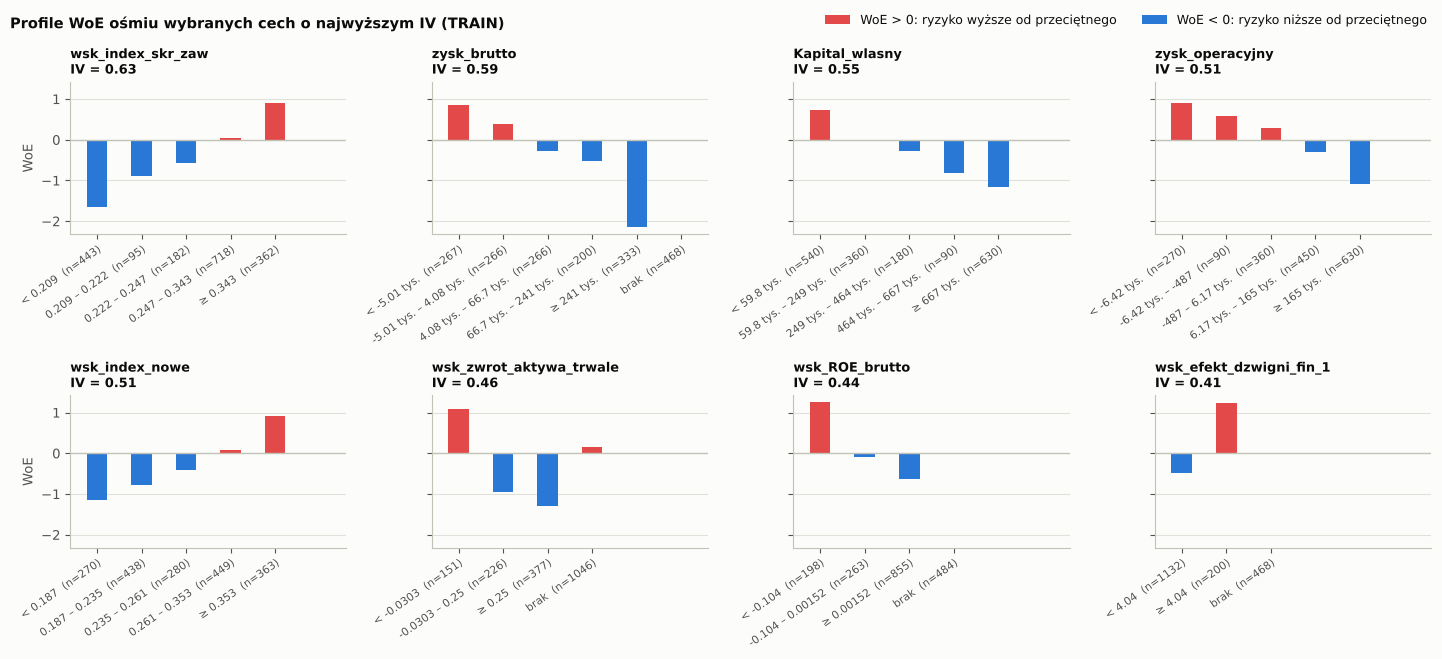

---wsk_index_skr_zaw  (IV = 0.635; indeks otoczenia)---


,koszyk,n,defaulty,DR (%),WoE
0,"[-inf, 0.2089)",443,5,1.13,-1.639
1,"[0.2089, 0.2222)",95,2,2.11,-0.882
2,"[0.2222, 0.2471)",182,6,3.30,-0.562
3,"[0.2471, 0.3428)",718,45,6.27,0.045
4,"[0.3428, inf)",362,49,13.54,0.894


---zysk_brutto  (IV = 0.592; pozycja kwotowa [zł])---


,koszyk,n,defaulty,DR (%),WoE
0,"[-inf, -5013)",267,35,13.11,0.856
1,"[-5013, 4078)",266,23,8.65,0.397
2,"[4078, 6.667e+04)",266,12,4.51,-0.278
3,"[6.667e+04, 2.407e+05)",200,7,3.50,-0.515
4,"[2.407e+05, inf)",333,2,0.60,-2.152
5,brak,468,28,5.98,-0.002


---Kapital_wlasny  (IV = 0.550; pozycja kwotowa [zł])---


,koszyk,n,defaulty,DR (%),WoE
0,"[-inf, 5.983e+04)",540,64,11.85,0.740
1,"[5.983e+04, 2.492e+05)",360,21,5.83,-0.020
2,"[2.492e+05, 4.641e+05)",180,8,4.44,-0.271
3,"[4.641e+05, 6.665e+05)",90,2,2.22,-0.827
4,"[6.665e+05, inf)",630,12,1.90,-1.162


Monotoniczność WoE potwierdzona dla wszystkich 44 wybranych cech liczbowych.


In [33]:
def skrot(v):
    """Krótki zapis liczby na osi (tys., mln)."""
    if not np.isfinite(v):
        return "−∞" if v < 0 else "+∞"
    a = abs(v)
    if a >= 1e6:
        return f"{v / 1e6:.3g} mln"
    if a >= 1e3:
        return f"{v / 1e3:.3g} tys."
    return f"{v:.3g}"


def etykiety_koszykow(b):
    if b["kind"] == "cat":
        return [str(p).replace("_", " ") for p in b["levels"]]
    g = np.r_[-np.inf, b["edges"], np.inf]
    return [f"< {skrot(g[i + 1])}" if i == 0 else (f"≥ {skrot(g[i])}" if i == len(b["counts"]) - 1 else f"{skrot(g[i])} – {skrot(g[i + 1])}")
            for i in range(len(b["counts"]))]


PROFILE = woe.selected_[:8]
fig, axes = plt.subplots(2, 4, figsize=(14.5, 6.6), sharey=True)
for ax, c in zip(axes.ravel(), PROFILE):
    b, t = woe.bins_[c], woe.profile(c)
    etykiety = etykiety_koszykow(b) + (["brak"] if len(t) > len(b["counts"]) else [])
    ax.bar(np.arange(len(t)), t["WoE"], width=0.46, color=[K_WYZSZE if w > 0 else K_NIZSZE for w in t["WoE"]])
    ax.axhline(0, color=OS, lw=1)
    ax.set_xlim(-0.6, 5.6)                                   # stała szerokość słupków niezależnie od liczby koszyków
    ax.set_xticks(np.arange(len(t)), [f"{e}  (n={n})" for e, n in zip(etykiety, t["n"])], fontsize=7.8, rotation=35, ha="right", rotation_mode="anchor")
    ax.set_title(f"{c}\nIV = {b['iv']:.2f}", fontsize=9.3)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("WoE")
axes[0, 0].bar([np.nan], [np.nan], color=K_WYZSZE, label="WoE > 0: ryzyko wyższe od przeciętnego")
axes[0, 0].bar([np.nan], [np.nan], color=K_NIZSZE, label="WoE < 0: ryzyko niższe od przeciętnego")
fig.legend(loc="upper right", ncol=2, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("Profile WoE ośmiu wybranych cech o najwyższym IV (TRAIN)", x=0.01, ha="left", fontsize=10.5, fontweight="bold")
pokaz("10_profile_woe")

for c in PROFILE[:3]:
    print(f"---{c}  (IV = {woe.bins_[c]['iv']:.3f}; {META.at[c, 'formuła (z danych)'] or META.at[c, 'typ']})---")
    display(woe.profile(c).round({"DR (%)": 2, "WoE": 3}))

# kontrola: w każdej wybranej cesze liczbowej WoE jest monotoniczne względem wartości cechy
for c in woe.selected_:
    b = woe.bins_[c]
    if b["kind"] == "num" and len(b["woe"]) > 1:
        r = np.diff(b["woe"])
        assert (r >= 0).all() or (r <= 0).all(), f"brak monotoniczności: {c}"
print(f"Monotoniczność WoE potwierdzona dla wszystkich {sum(woe.bins_[c]['kind'] == 'num' for c in woe.selected_)} wybranych cech liczbowych.")

**Wnioski.**
* Profile są monotoniczne i czytelne ekonomicznie. Przykłady: strata brutto większa niż 5 tys. zł to DR 13,1%, a zysk powyżej 241 tys. zł — 0,6%; kapitał własny poniżej 60 tys. zł to DR 11,9%, powyżej 667 tys. zł — 1,9%; najniższy przedział `wsk_index_skr_zaw` to DR 1,1%, najwyższy — 13,5%.
* Koszyk „brak” ma WoE bliskie zera tam, gdzie oznacza brak informacji o wyniku finansowym (jednostki mikro) — model nie będzie tych firm ani karał, ani nagradzał. Inaczej jest we wskaźnikach, w których brak sam coś znaczy (np. `wsk_zwrot_aktywa_trwale`: firma bez środków trwałych — WoE lekko dodatnie).
* Liczba koszyków jest mała (2–5 oraz ewentualny koszyk braków), a każdy zawiera co najmniej 5% obserwacji — tyle „rozdzielczości” da się wiarygodnie oszacować przy 107 defaultach.

### 5.7. Stabilność binningu i selekcji w walidacji krzyżowej

IV policzone na tych samych danych, na których dobierano koszyki, jest optymistyczne. Dlatego cały pipeline WoE dopasowujemy osobno w każdym z 5 foldów (na części uczącej) i sprawdzamy: (1) jak zmienia się IV, (2) czy cecha jest wybierana za każdym razem, (3) jaką moc ma jej WoE na części walidacyjnej folda, której binning „nie widział” (Gini out-of-fold).

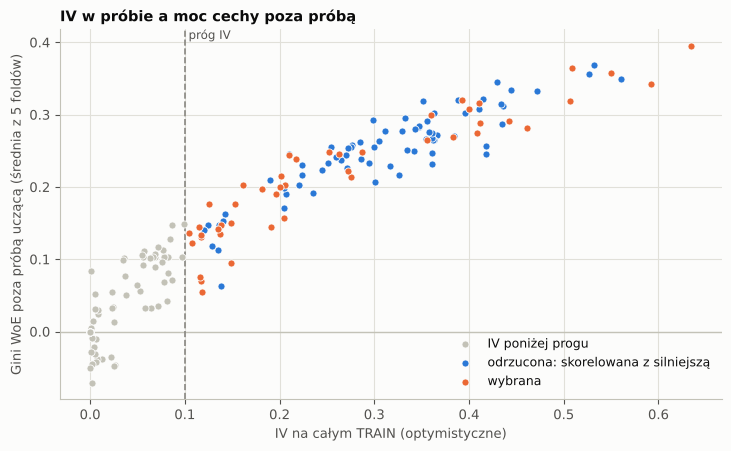

---Korelacja rang IV (TRAIN) z Gini out-of-fold: 0.962 ---


,liczba cech,mediana IV (TRAIN),mediana Gini out-of-fold,odsetek z Gini OOF > 0 (%)
status (TRAIN),,,,
IV poniżej progu,77,0.024,0.029,55.844
korelacja z,75,0.316,0.255,100.000
wybrana,45,0.205,0.213,100.000


Spośród 45 cech wybranych na TRAIN: 17 wybrano we wszystkich 5 foldach, a dla 31 w każdym foldzie wybrano tę cechę lub cechę z tego samego klastra korelacji.
---Cechy wybrane na TRAIN: stabilność (20 o najwyższym IV)---


,IV (TRAIN),IV w foldach: średnia,IV w foldach: odch. std.,wybrana w foldach (z 5),Gini out-of-fold,klaster wybrany w foldach (z 5)
wsk_index_skr_zaw,0.635,0.623,0.050,5,0.394,5
zysk_brutto,0.592,0.613,0.108,3,0.342,5
Kapital_wlasny,0.550,0.580,0.023,5,0.358,5
zysk_operacyjny,0.509,0.523,0.061,3,0.365,5
wsk_index_nowe,0.506,0.535,0.086,5,0.319,5
wsk_zwrot_aktywa_trwale,0.461,0.463,0.082,5,0.282,5
wsk_ROE_brutto,0.442,0.435,0.057,2,0.291,5
wsk_efekt_dzwigni_fin_1,0.412,0.409,0.048,5,0.289,5
wsk_efekt_dzwigni_fin_2,0.411,0.421,0.049,5,0.315,5
wsk_struktura_kap_obcego_s,0.408,0.406,0.046,2,0.274,5


In [34]:
iv_fold, wybor_fold, gini_oof, PIPE_FOLD = [], [], [], []
for i_tr, i_va in FOLDY:
    p = pipeline_woe(iv_min=IV_MIN).fit(X_train.iloc[i_tr], y_train.iloc[i_tr])
    PIPE_FOLD.append(p)
    w = p.named_steps["woe"]
    X_va = p[:-1].transform(X_train.iloc[i_va])                                   # cechy części walidacyjnej przed kodowaniem WoE
    y_va = y_train.iloc[i_va].to_numpy()
    iv_fold.append(w.iv_table_["IV"])
    wybor_fold.append(pd.Series(1, index=w.selected_))
    gini_oof.append(pd.Series({c: 2 * roc_auc_score(y_va, apply_bins(w.bins_[c], X_va[c].to_numpy())) - 1 for c in w.bins_}))
STAB = pd.DataFrame({"IV (TRAIN)": IV["IV"]})
STAB["IV w foldach: średnia"] = pd.concat(iv_fold, axis=1).mean(axis=1).reindex(STAB.index)
STAB["IV w foldach: odch. std."] = pd.concat(iv_fold, axis=1).std(axis=1).reindex(STAB.index)
STAB["wybrana w foldach (z 5)"] = pd.concat(wybor_fold, axis=1).sum(axis=1).reindex(STAB.index).fillna(0).astype(int)
STAB["Gini out-of-fold"] = pd.concat(gini_oof, axis=1).mean(axis=1).reindex(STAB.index)
STAB["status (TRAIN)"] = IV["status"].str.split(":").str[0]
# stabilność na poziomie klastra korelacji (p. 4.4): czy w foldzie wybrano tę cechę LUB jej bliski zamiennik?
wybrane_w_foldach = [set(s.index) for s in wybor_fold]
STAB["klaster wybrany w foldach (z 5)"] = [
    sum(bool(set(KLASTER.index[KLASTER == KLASTER[c]]) & w) for w in wybrane_w_foldach) if c in KLASTER.index else STAB.at[c, "wybrana w foldach (z 5)"]
    for c in STAB.index]

fig, ax = plt.subplots(figsize=(7.4, 4.6))
for status, kolor, etykieta in (("IV poniżej progu", K_TLO_SERII, "IV poniżej progu"), ("korelacja z", K_SERIA, "odrzucona: skorelowana z silniejszą"), ("wybrana", K_AKCENT, "wybrana")):
    m = STAB["status (TRAIN)"] == status
    ax.scatter(STAB.loc[m, "IV (TRAIN)"], STAB.loc[m, "Gini out-of-fold"], s=26, color=kolor, edgecolor=TLO, linewidth=0.6, label=etykieta, zorder=3)
ax.axhline(0, color=OS, lw=1)
ax.axvline(IV_MIN, color=SZARY, lw=1.2, ls="--")
ax.text(IV_MIN, ax.get_ylim()[1], " próg IV", fontsize=8.5, color=TUSZ2, va="top")
ax.set(xlabel="IV na całym TRAIN (optymistyczne)", ylabel="Gini WoE poza próbą uczącą (średnia z 5 foldów)", title="IV w próbie a moc cechy poza próbą")
ax.legend(loc="lower right")
pokaz("11_iv_a_gini_oof")

print("---Korelacja rang IV (TRAIN) z Gini out-of-fold:", round(float(STAB["IV (TRAIN)"].corr(STAB["Gini out-of-fold"], method="spearman")), 3), "---")
display(STAB.groupby("status (TRAIN)").agg(**{"liczba cech": ("IV (TRAIN)", "size"), "mediana IV (TRAIN)": ("IV (TRAIN)", "median"),
                                              "mediana Gini out-of-fold": ("Gini out-of-fold", "median"),
                                              "odsetek z Gini OOF > 0 (%)": ("Gini out-of-fold", lambda s: (s > 0).mean() * 100)}).round(3))
wyb = STAB.loc[woe.selected_]
print(f"Spośród {len(wyb)} cech wybranych na TRAIN: {int((wyb['wybrana w foldach (z 5)'] == 5).sum())} wybrano we wszystkich 5 foldach,"
      f" a dla {int((wyb['klaster wybrany w foldach (z 5)'] == 5).sum())} w każdym foldzie wybrano tę cechę lub cechę z tego samego klastra korelacji.")
print("---Cechy wybrane na TRAIN: stabilność (20 o najwyższym IV)---")
display(wyb.drop(columns="status (TRAIN)").head(20).round(3))

**Wnioski.**
* **Ranking IV jest wiarygodny:** korelacja rang między IV liczonym w próbie a mocą cechy poza próbą wynosi 0,96. Wszystkie 120 cech powyżej progu zachowuje dodatni Gini poza próbą uczącą, podczas gdy wśród cech poniżej progu dodatni Gini ma tylko 56% (mediana 0,03) — niewiele więcej, niż dałby rzut monetą. Próg 0,10 dobrze oddziela sygnał od szumu.
* **IV jest optymistyczne, ale umiarkowanie:** najsilniejsze cechy mają poza próbą Gini 0,32–0,39 — mniej, niż sugerowałoby IV > 0,5, lecz wciąż dużo.
* **Wybór konkretnej cechy bywa niestabilny, wybór „tematu” — stabilny.** Tylko 17 z 45 cech jest wybieranych we wszystkich pięciu foldach, ale dla 31 w każdym foldzie wybierana jest ta cecha *albo jej bliski zamiennik z tego samego klastra korelacji* (np. `zysk_brutto` wymienia się z `wsk_ebit` i `zysk_netto`). To bezpośrednia konsekwencja redundancji cech i ważna wskazówka na później: stabilność wyjaśnień obu modeli należy oceniać na poziomie grup cech, a nie pojedynczych zmiennych.
* Najsłabsze z wybranych cech (IV 0,10–0,15) są wybierane tylko w części foldów — to pierwsi kandydaci do odrzucenia przez limit `max_features`.

### 5.8. Capping i standaryzacja: cechy dla modelu black-box

In [35]:
pipe_bb = pipeline_blackbox()                                             # wariant dla modeli drzewiastych: capping, braki natywne
pipe_bb_skal = pipeline_blackbox(log=True, impute=True, scale=True)       # wariant dla SVM / sieci: + logarytm ze znakiem, imputacja, standaryzacja
X_train_bb, X_valid_bb = pipe_bb.fit_transform(X_train, y_train), pipe_bb.transform(X_valid)
X_train_bbs, X_valid_bbs = pipe_bb_skal.fit_transform(X_train, y_train), pipe_bb_skal.transform(X_valid)
fc_bb, fc_bbs = pipe_bb.named_steps["czyszczenie"], pipe_bb_skal.named_steps["czyszczenie"]

przyklady_cap = ["Kapital_wlasny", "zysk_brutto", "wsk_zadluzenie_kap_wlasnego", "wsk_ROE_brutto", "wsk_index_nowe"]
surowe_valid = pipe_bb[:2].transform(X_valid)                             # VALID po dwóch pierwszych krokach (przed cappingiem)
display(pd.DataFrame({
    "p1 (TRAIN) = dolna granica": fc_bb.lo_[przyklady_cap], "p99 (TRAIN) = górna granica": fc_bb.hi_[przyklady_cap],
    "max przed cappingiem (TRAIN)": pipe_bb[:2].transform(X_train)[przyklady_cap].max(), "max po cappingu (TRAIN)": X_train_bb[przyklady_cap].max(),
    "przycięte w VALID (%)": ((surowe_valid[przyklady_cap] < fc_bb.lo_[przyklady_cap]) | (surowe_valid[przyklady_cap] > fc_bb.hi_[przyklady_cap])).mean() * 100,
}).round(3))

num_bbs = fc_bbs.cols_
print(f"Wariant drzewiasty:  {X_train_bb.shape[1]} cech ({len(fc_bb.cols_)} liczbowych + {X_train_bb.shape[1] - len(fc_bb.cols_)} kolumn one-hot); braki zachowane: {int(X_train_bb.isna().sum().sum())} komórek")
print(f"Wariant skalowany:   {X_train_bbs.shape[1]} cech ({len(num_bbs)} liczbowych + {len(fc_bbs.ind_cols_)} flag braku + {X_train_bbs.shape[1] - len(num_bbs) - len(fc_bbs.ind_cols_)} kolumn one-hot);"
      f" braki: {int(X_train_bbs.isna().sum().sum())}")
print(f"Standaryzacja (parametry z TRAIN): średnia cech na TRAIN od {X_train_bbs[num_bbs].mean().min():+.3f} do {X_train_bbs[num_bbs].mean().max():+.3f}, odchylenie od {X_train_bbs[num_bbs].std(ddof=0).min():.3f} do {X_train_bbs[num_bbs].std(ddof=0).max():.3f}")
print(f"Te same parametry zastosowane do VALID: średnia cech od {X_valid_bbs[num_bbs].mean().min():+.3f} do {X_valid_bbs[num_bbs].mean().max():+.3f}, odchylenie od {X_valid_bbs[num_bbs].std(ddof=0).min():.3f} do {X_valid_bbs[num_bbs].std(ddof=0).max():.3f}")
print(f"Odsetek wartości z |z| > 5 po standaryzacji: TRAIN {(np.abs(X_train_bbs[num_bbs].to_numpy()) > 5).mean():.2%}, VALID {(np.abs(X_valid_bbs[num_bbs].to_numpy()) > 5).mean():.2%}")
print("Cechy usunięte w czyszczeniu (wariant drzewiasty):", {k: len(v) for k, v in fc_bb.dropped_.items()})

,p1 (TRAIN) = dolna granica,p99 (TRAIN) = górna granica,max przed cappingiem (TRAIN),max po cappingu (TRAIN),przycięte w VALID (%)
Kapital_wlasny,0.000,3.759334e+07,6.313234e+08,3.759334e+07,1.500
zysk_brutto,-1798566.733,3.883515e+06,3.450119e+07,3.883515e+06,1.833
wsk_zadluzenie_kap_wlasnego,0.000,5.553700e+01,7.538160e+02,5.553700e+01,1.333
wsk_ROE_brutto,-6.462,1.211000e+00,6.350000e+01,1.211000e+00,1.000
wsk_index_nowe,0.106,5.680000e-01,7.650000e-01,5.680000e-01,1.667


Wariant drzewiasty:  218 cech (193 liczbowych + 25 kolumn one-hot); braki zachowane: 53326 komórek
Wariant skalowany:   259 cech (193 liczbowych + 41 flag braku + 25 kolumn one-hot); braki: 0
Standaryzacja (parametry z TRAIN): średnia cech na TRAIN od -0.000 do +0.000, odchylenie od 1.000 do 1.000
Te same parametry zastosowane do VALID: średnia cech od -0.137 do +0.103, odchylenie od 0.474 do 1.160
Odsetek wartości z |z| > 5 po standaryzacji: TRAIN 0.37%, VALID 0.31%
Cechy usunięte w czyszczeniu (wariant drzewiasty): {'duplikaty': 9, 'za dużo braków': 7, 'quasi-stałe': 8, 'stałe po winsoryzacji': 0}


**Wnioski.**
* Granice winsoryzacji pochodzą wyłącznie ze zbioru treningowego; zastosowane do zbioru walidacyjnego przycinają 1–2% wartości każdej cechy, czyli tyle, ile wynika z definicji percentyli 1–99 — capping „przenosi się” na nowe dane.
* Skala problemu, który capping rozwiązuje: maksimum `Kapital_wlasny` to 631 mln zł przy 99. percentylu 38 mln zł, a maksimum `wsk_zadluzenie_kap_wlasnego` to 754 przy 99. percentylu 56.
* Wariant domyślny (dla modeli drzewiastych) zachowuje braki danych — gradient boosting obsługuje je natywnie, więc niczego nie imputujemy. Wariant dla modeli wrażliwych na skalę dodaje logarytm ze znakiem, imputację medianą z flagami braku i standaryzację; po standaryzacji średnie i odchylenia są równe 0 i 1 **tylko na zbiorze treningowym** — na walidacyjnym odbiegają, bo parametry nie były na nim liczone, i tak właśnie ma być.
* Wybór wariantu należy do etapu modelowania; oba są gotowe i oba uczą się wyłącznie w `fit`.

### 5.9. Zbiory wynikowe i kontrola „kontraktu” cech

In [36]:
X_valid_woe = pipe_woe.transform(X_valid)
kontrakt = pd.DataFrame({
    "wymiar TRAIN": {"WoE (model interpretowalny)": X_train_woe.shape, "black-box: drzewiasty": X_train_bb.shape, "black-box: skalowany": X_train_bbs.shape},
    "wymiar VALID": {"WoE (model interpretowalny)": X_valid_woe.shape, "black-box: drzewiasty": X_valid_bb.shape, "black-box: skalowany": X_valid_bbs.shape},
    "te same kolumny": {"WoE (model interpretowalny)": list(X_train_woe.columns) == list(X_valid_woe.columns),
                        "black-box: drzewiasty": list(X_train_bb.columns) == list(X_valid_bb.columns),
                        "black-box: skalowany": list(X_train_bbs.columns) == list(X_valid_bbs.columns)},
    "braki w VALID": {"WoE (model interpretowalny)": int(X_valid_woe.isna().sum().sum()), "black-box: drzewiasty": int(X_valid_bb.isna().sum().sum()),
                      "black-box: skalowany": int(X_valid_bbs.isna().sum().sum())},
    "wartości nieskończone": {"WoE (model interpretowalny)": int(np.isinf(X_valid_woe.to_numpy()).sum()), "black-box: drzewiasty": int(np.isinf(X_valid_bb.to_numpy(dtype=float)).sum()),
                              "black-box: skalowany": int(np.isinf(X_valid_bbs.to_numpy(dtype=float)).sum())},
})
display(kontrakt)
assert kontrakt["te same kolumny"].all() and kontrakt.loc[["WoE (model interpretowalny)", "black-box: skalowany"], "braki w VALID"].sum() == 0
assert kontrakt["wartości nieskończone"].sum() == 0

# odporność na dane „z produkcji”: nieznana kategoria, wartości spoza zakresu uczenia, nowe braki
proba = X_valid.head(3).copy()
proba["pkdKod"] = [9999, 9900, 5]                        # kody spoza zbioru uczącego
proba["formaWlasnosci_Symbol"] = [999, 0, 214]
proba["Kapital_wlasny"] = [1e15, -1e15, np.nan]
proba["zysk_brutto"] = [np.inf, -np.inf, np.nan]
wynik_woe, wynik_bb = pipe_woe.transform(proba), pipe_bb_skal.transform(proba)
assert np.isfinite(wynik_woe.to_numpy()).all() and np.isfinite(wynik_bb.to_numpy(dtype=float)).all()
print("Test odporności: nieznane kody, wartości ±1e15, ±inf i NaN zostały przetworzone bez błędów; wynik jest skończony w obu pipeline'ach.")

psi_woe = pd.Series({c: psi(X_train_woe[c], X_valid_woe[c]) for c in X_train_woe.columns})
print(f"Stabilność rozkładu cech WoE, TRAIN → VALID (bez użycia targetu): mediana PSI {psi_woe.median():.3f}, maksimum {psi_woe.max():.3f} ({psi_woe.idxmax()})")

,wymiar TRAIN,wymiar VALID,te same kolumny,braki w VALID,wartości nieskończone
WoE (model interpretowalny),"(1800, 45)","(600, 45)",True,0,0
black-box: drzewiasty,"(1800, 218)","(600, 218)",True,18072,0
black-box: skalowany,"(1800, 259)","(600, 259)",True,0,0


Test odporności: nieznane kody, wartości ±1e15, ±inf i NaN zostały przetworzone bez błędów; wynik jest skończony w obu pipeline'ach.
Stabilność rozkładu cech WoE, TRAIN → VALID (bez użycia targetu): mediana PSI 0.004, maksimum 0.022 (woe__wsk_koszty_przychody)


**Wnioski.** Trzy zestawy cech mają na zbiorze treningowym i walidacyjnym identyczne kolumny, nie zawierają wartości nieskończonych, a tam, gdzie model tego wymaga — także braków. Pipeline'y poprawnie obsługują dane, jakich nie było w uczeniu (nieznane kody, wartości skrajne, nowe braki), a rozkłady cech WoE są stabilne między TRAIN a VALID (PSI nie przekracza 0,03).

Do etapu modelowania przekazujemy **fabryki pipeline'ów** (`pipeline_woe`, `pipeline_blackbox`), a nie gotowe macierze cech — po to, żeby przygotowanie cech było dopasowywane od nowa wewnątrz każdego folda:

```python
model_logit = Pipeline(pipeline_woe(max_features=10).steps + [("logit", LogisticRegression(max_iter=1000))])
cross_val_score(model_logit, X_train, y_train, cv=FOLDY, scoring="roc_auc")
```

## ETAP 6. Kontrola przecieku danych — testy

Zasady z p. 2.6 sprawdzamy teraz empirycznie. Używamy do tego prostych modeli-sond (regresja logistyczna na cechach WoE oraz gradient boosting z płytkimi drzewami na cechach surowych). **To nie są jeszcze modele projektu** — nie są strojone ani kalibrowane; służą wyłącznie do zmierzenia, czy przygotowane cechy niosą sygnał i czy sposób ich przygotowania nie zawyża wyników.

### 6.1. Test dymny: czy pipeline'y działają w walidacji krzyżowej?

In [37]:
def auc_cv(pipeline, X, y, foldy):
    """AUC w walidacji krzyżowej. Cały pipeline (przygotowanie cech + model) jest w każdym foldzie dopasowywany od zera na części uczącej."""
    wyniki = []
    for i_tr, i_va in foldy:
        model = clone(pipeline).fit(X.iloc[i_tr], y.iloc[i_tr])
        wyniki.append(roc_auc_score(y.iloc[i_va], model.predict_proba(X.iloc[i_va])[:, 1]))
    return np.array(wyniki)


def sonda_logit(max_features=10, iv_min=IV_MIN):
    return Pipeline(pipeline_woe(iv_min=iv_min, max_features=max_features).steps + [("logit", LogisticRegression(max_iter=1000))])


def sonda_gbm():
    return Pipeline(pipeline_blackbox().steps + [("gbm", HistGradientBoostingClassifier(max_depth=2, learning_rate=0.05, max_iter=150, random_state=RNG_SEED))])


auc_logit = auc_cv(sonda_logit(), X_train, y_train, FOLDY_REP)
auc_gbm = auc_cv(sonda_gbm(), X_train, y_train, FOLDY)
display(pd.DataFrame({"AUC CV (średnia)": [auc_logit.mean(), auc_gbm.mean()], "odch. std. między foldami": [auc_logit.std(), auc_gbm.std()],
                      "min": [auc_logit.min(), auc_gbm.min()], "max": [auc_logit.max(), auc_gbm.max()], "liczba foldów": [len(auc_logit), len(auc_gbm)]},
                     index=["sonda: regresja logistyczna, 10 cech WoE", "sonda: gradient boosting, cechy surowe po cappingu"]).round(3))

,AUC CV (średnia),odch. std. między foldami,min,max,liczba foldów
"sonda: regresja logistyczna, 10 cech WoE",0.772,0.029,0.708,0.815,25
"sonda: gradient boosting, cechy surowe po cappingu",0.783,0.015,0.756,0.800,5


**Wniosek.** Oba pipeline'y działają od początku do końca wewnątrz walidacji krzyżowej i dają zbliżony, sensowny wynik: AUC ok. 0,77 dla sondy logitowej (10 cech WoE) i ok. 0,78 dla sondy boostingowej. To punkt odniesienia dla etapu modelowania, a zarazem pierwsza obserwacja warta zapamiętania: prosty model addytywny niemal dorównuje nieliniowemu, co sugeruje, że zależności w danych są w dużej mierze monotoniczne i addytywne (sondy nie były strojone, więc nie jest to jeszcze porównanie modeli). Rozrzut między foldami (od 0,71 do 0,82 dla sondy logitowej) potwierdza szacunki z p. 2.1 — pojedynczy fold mówi niewiele.

### 6.2. „Zbyt dobre” predyktory i zmienne nieopisane

Przeciek często ujawnia się jako cecha, która przewiduje target podejrzanie dobrze. Sprawdzamy więc: (a) najwyższą moc pojedynczej cechy, (b) czy istnieje koszyk o niemal stuprocentowej (lub zerowej) częstości defaultów, (c) jak bardzo wynik zależy od nieopisanych indeksów `wsk_index_*`.

In [38]:
najsilniejsza = STAB["Gini out-of-fold"].idxmax()
print(f"(a) Najwyższy Gini pojedynczej cechy: w próbie {SILA['Gini'].max():.3f} ({SILA['Gini'].idxmax()}), poza próbą {STAB['Gini out-of-fold'].max():.3f} ({najsilniejsza})"
      f"  ->  AUC ok. {(STAB['Gini out-of-fold'].max() + 1) / 2:.2f}; idealna separacja to Gini = 1")

koszyki = pd.concat([woe.profile(c).assign(cecha=c) for c in woe.bins_], ignore_index=True)
koszyki = koszyki[koszyki["n"] >= 90]
k_max, k_min = koszyki.loc[koszyki["DR (%)"].idxmax()], koszyki.loc[koszyki["DR (%)"].idxmin()]
print(f"(b) Najbardziej ryzykowny koszyk wśród wszystkich {len(woe.bins_)} cech: DR = {k_max['DR (%)']:.1f}% ({k_max['cecha']}, {k_max['koszyk']}, n = {k_max['n']});"
      f" najbezpieczniejszy: DR = {k_min['DR (%)']:.1f}% ({k_min['cecha']}, n = {k_min['n']})")

auc_bez = auc_cv(sonda_logit(), X_train.drop(columns=INDEKSY), y_train, FOLDY_REP)
roznica = auc_logit - auc_bez
print(f"(c) Sonda logitowa, AUC CV ({len(FOLDY_REP)} foldów): ze zmiennymi wsk_index_* {auc_logit.mean():.3f}, bez nich {auc_bez.mean():.3f};"
      f" różnica {roznica.mean():+.3f} (dodatnia w {int((roznica > 0).sum())} z {len(roznica)} foldów)")
display(IV.loc[INDEKSY, ["IV", "koszyki", "kierunek ryzyka", "status"]].join(STAB.loc[INDEKSY, ["wybrana w foldach (z 5)", "Gini out-of-fold"]]).round(3))

(a) Najwyższy Gini pojedynczej cechy: w próbie 0.494 (wsk_zwrot_aktywa_trwale), poza próbą 0.394 (wsk_index_skr_zaw)  ->  AUC ok. 0.70; idealna separacja to Gini = 1
(b) Najbardziej ryzykowny koszyk wśród wszystkich 197 cech: DR = 21.2% (wsk_ROE, [-inf, -0.2493), n = 132); najbezpieczniejszy: DR = 0.6% (zysk_brutto, n = 333)
(c) Sonda logitowa, AUC CV (25 foldów): ze zmiennymi wsk_index_* 0.772, bez nich 0.709; różnica +0.063 (dodatnia w 23 z 25 foldów)


,IV,koszyki,kierunek ryzyka,status,wybrana w foldach (z 5),Gini out-of-fold
wsk_index_aktywne,0.058,4,rosnący,IV poniżej progu,1,0.033
wsk_index_skr_zaw,0.635,5,rosnący,wybrana,5,0.394
wsk_index_nowe,0.506,5,rosnący,wybrana,5,0.319


**Wnioski.**
* **Brak oznak przecieku przez cechy.** Najsilniejsza pojedyncza cecha ma poza próbą Gini 0,39 (AUC ok. 0,70) — daleko od idealnej separacji. Żaden koszyk żadnej cechy nie jest „czysty”: najbardziej ryzykowny ma DR 21%, najbezpieczniejszy 0,6%. Wysokie IV (> 0,5) wynika z dużej rozpiętości DR między skrajnymi koszykami, a nie z istnienia cechy „znającej odpowiedź”.
* **Indeksy otoczenia są najważniejszym pojedynczym źródłem informacji.** Bez `wsk_index_*` AUC sondy spada z 0,77 do 0,71 (różnica 0,06, dodatnia w 23 z 25 foldów). `wsk_index_skr_zaw` i `wsk_index_nowe` są wybierane w każdym foldzie; `wsk_index_aktywne` nie niesie informacji.
* **Ocena ryzyka.** Zmienne te (1) nie są opisane w słowniku, (2) są cechami otoczenia firmy, a nie samej firmy (p. 1.5), (3) nie wiemy, z jakiego okresu pochodzą. Jeżeli `wsk_index_skr_zaw` (sądząc po nazwie: udział podmiotów skreślonych lub zawieszonych) liczono w okresie, w którym obserwowano defaulty, to mógłby częściowo „zawierać” zdarzenie, które przewidujemy. Na podstawie samych danych nie da się tego rozstrzygnąć. Przeciw tej hipotezie przemawia fakt, że niemal równie silny jest `wsk_index_nowe` (udział podmiotów nowych), którego z defaultów wyprowadzić się nie da.
* **Decyzja:** indeksy zostają w zbiorze kandydatów, ale (1) ich definicję trzeba potwierdzić w dokumentacji lub u prowadzącego, (2) na etapie modelowania oba modele raportujemy w dwóch wariantach — z indeksami i bez — a wybór wariantu uzasadniamy, (3) w wyjaśnieniach modeli wkład indeksów pokazujemy osobno.

### 6.3. Eksperyment: ile „kosztuje” przeciek przez przygotowanie cech?

Porównujemy dwa sposoby oceny tej samej sondy (10 cech WoE o najwyższym IV + regresja logistyczna):
* **poprawnie** — binning, WoE i selekcja cech są dopasowywane w każdym foldzie od nowa, tylko na jego części uczącej (cały `Pipeline` wewnątrz CV);
* **z przeciekiem** — binning, WoE i selekcję wykonano raz, na całym zbiorze treningowym, a walidacja krzyżowa obejmuje już tylko regresję logistyczną (typowy błąd: „najpierw przygotuję cechy, potem zrobię CV”).

Oba warianty liczymy dla targetu prawdziwego oraz dla targetu **spermutowanego**, w którym z konstrukcji nie ma żadnego sygnału — uczciwa procedura musi wtedy dać AUC ≈ 0,5.

AUC CV (średnia)    min    max  liczba powtórzeń
scenariusz          procedura                                                      
target prawdziwy    poprawnie                 0.761  0.761  0.761               1.0
                    z przeciekiem             0.827  0.827  0.827               1.0
target spermutowany poprawnie                 0.501  0.478  0.528               5.0
                    z przeciekiem             0.679  0.644  0.716               5.0

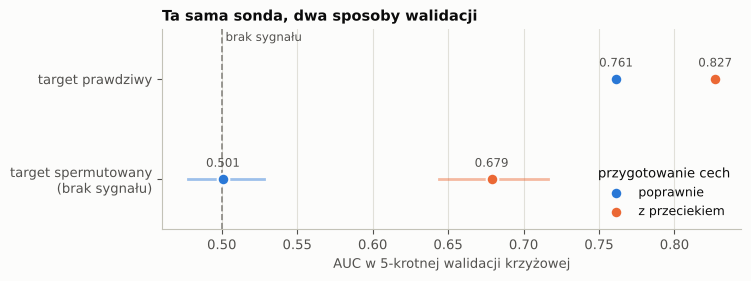

In [39]:
def auc_cv_z_przeciekiem(X, y, foldy):
    """BŁĘDNA procedura (celowo): cechy WoE i ich selekcja powstają raz na całym zbiorze, CV obejmuje tylko model."""
    Z = pipeline_woe(iv_min=0.0, max_features=10).fit_transform(X, y)
    return np.array([roc_auc_score(y.iloc[i_va], LogisticRegression(max_iter=1000).fit(Z.iloc[i_tr], y.iloc[i_tr]).predict_proba(Z.iloc[i_va])[:, 1])
                     for i_tr, i_va in foldy])


N_PERM = 5
rs = np.random.RandomState(RNG_SEED)
wyniki = {("target prawdziwy", "poprawnie"): [auc_cv(sonda_logit(iv_min=0.0), X_train, y_train, FOLDY).mean()],
          ("target prawdziwy", "z przeciekiem"): [auc_cv_z_przeciekiem(X_train, y_train, FOLDY).mean()],
          ("target spermutowany", "poprawnie"): [], ("target spermutowany", "z przeciekiem"): []}
for _ in range(N_PERM):
    y_perm = pd.Series(rs.permutation(y_train.to_numpy()), index=y_train.index)
    foldy_perm = list(StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RNG_SEED).split(X_train, y_perm))
    wyniki[("target spermutowany", "poprawnie")].append(auc_cv(sonda_logit(iv_min=0.0), X_train, y_perm, foldy_perm).mean())
    wyniki[("target spermutowany", "z przeciekiem")].append(auc_cv_z_przeciekiem(X_train, y_perm, foldy_perm).mean())
PRZECIEK = pd.DataFrame({k: {"AUC CV (średnia)": np.mean(v), "min": np.min(v), "max": np.max(v), "liczba powtórzeń": len(v)} for k, v in wyniki.items()}).T
PRZECIEK.index.names = ["scenariusz", "procedura"]
display(PRZECIEK.round(3))

fig, ax = plt.subplots(figsize=(7.6, 2.9))
for i, scen in enumerate(["target spermutowany", "target prawdziwy"]):
    for proc, kolor in (("poprawnie", K_SERIA), ("z przeciekiem", K_AKCENT)):
        v = wyniki[(scen, proc)]
        ax.plot([np.min(v), np.max(v)], [i, i], color=kolor, lw=2, alpha=0.45)
        ax.scatter([np.mean(v)], [i], s=70, color=kolor, edgecolor=TLO, linewidth=1.5, zorder=3, label=proc if i == 0 else None)
        ax.annotate(f"{np.mean(v):.3f}", (np.mean(v), i), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5, color=TUSZ2)
ax.axvline(0.5, color=SZARY, lw=1.2, ls="--")
ax.text(0.5, 1.47, " brak sygnału", fontsize=8.5, color=TUSZ2, va="top")
ax.set_yticks([0, 1], ["target spermutowany\n(brak sygnału)", "target prawdziwy"])
ax.set(xlabel="AUC w 5-krotnej walidacji krzyżowej", ylim=(-0.5, 1.5), title="Ta sama sonda, dwa sposoby walidacji")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", title="przygotowanie cech")
pokaz("12_eksperyment_przeciek")

**Wnioski.**
* Na **spermutowanym targecie** procedura poprawna daje AUC = 0,50 (od 0,48 do 0,53) — dokładnie tyle, ile powinna, gdy sygnału nie ma. Procedura z przeciekiem „znajduje” AUC = 0,68 w czystym szumie: wybór 10 najlepszych z niemal 200 cech i dopasowanie WoE na całym zbiorze wystarczają, by walidacja krzyżowa pokazała moc predykcyjną, której nie ma.
* Na **prawdziwym targecie** przeciek zawyża AUC z 0,76 do 0,83, czyli o ok. 0,07 — to więcej niż różnice, jakich można się spodziewać między modelem interpretowalnym a black-box. Porównanie modeli na cechach przygotowanych „przed CV” byłoby więc bezwartościowe.
* Test permutacyjny warto powtórzyć dla finalnych modeli (razem ze strojeniem): jeżeli cała procedura na spermutowanym targecie da AUC wyraźnie powyżej 0,5, to gdzieś jest przeciek.

### 6.4. Testy własności pipeline'ów

In [40]:
# (1) Każdy fold ma własne parametry transformacji - dowód, że w CV nic nie jest „dziedziczone” z całego zbioru.
c = "zysk_brutto"
print(f"(1) Granice koszyków cechy {c} dopasowane w kolejnych foldach (tys. zł):")
for nr, p in enumerate(PIPE_FOLD, start=1):
    w = p.named_steps["woe"]
    print(f"    fold {nr}: {np.round(w.bins_[c]['edges'] / 1000, 1).tolist()} | wybranych cech: {len(w.selected_)}")
print(f"    cały TRAIN: {np.round(woe.bins_[c]['edges'] / 1000, 1).tolist()} | wybranych cech: {len(woe.selected_)}")

# (2) Transformacja obserwacji nie zależy od pozostałych obserwacji w przetwarzanej paczce (brak statystyk liczonych w `transform`).
for nazwa, p in (("WoE", pipe_woe), ("black-box (drzewiasty)", pipe_bb), ("black-box (skalowany)", pipe_bb_skal)):
    calosc = p.transform(X_valid).iloc[:5]
    pojedynczo = pd.concat([p.transform(X_valid.iloc[[i]]) for i in range(5)])
    assert np.allclose(calosc.to_numpy(dtype=float), pojedynczo.to_numpy(dtype=float), equal_nan=True), nazwa
print("(2) Wynik transformacji pojedynczej obserwacji jest identyczny jak w paczce 600 obserwacji - we wszystkich trzech pipeline'ach.")

# (3) Kroki nienadzorowane nie korzystają z targetu: dopasowanie ze spermutowanym y daje identyczne cechy.
y_los = pd.Series(np.random.RandomState(0).permutation(y_train.to_numpy()), index=y_train.index)
assert pipeline_blackbox().fit(X_train, y_los).transform(X_valid).equals(X_valid_bb)
print("(3) Pipeline black-box (czyszczenie, capping, one-hot) nie używa targetu - spermutowanie y nie zmienia żadnej cechy.")

# (4) Ponowne dopasowanie daje identyczny wynik (determinizm) i nie modyfikuje danych wejściowych.
kopia = X_train.copy()
assert pipeline_woe(iv_min=IV_MIN).fit(X_train, y_train).transform(X_valid).equals(X_valid_woe) and X_train.equals(kopia)
print("(4) Pipeline WoE jest deterministyczny i nie zmienia danych wejściowych.")

# (5) Indeks rekordu nie jest cechą; zbiory uczące pozostają rozłączne z testem.
assert not any("index" == k.lower() or "unnamed" in k.lower() for k in X_train.columns) and not set(X_train.index) & set(X_test.index)
print("(5) Wśród cech nie ma indeksu ani numeru wiersza; TRAIN i TEST są rozłączne.")

(1) Granice koszyków cechy zysk_brutto dopasowane w kolejnych foldach (tys. zł):
    fold 1: [-18.1, 12.8, 165.4] | wybranych cech: 46
    fold 2: [-18.6, 10.5, 155.4] | wybranych cech: 46
    fold 3: [-4.9, 5.0, 45.4, 261.4] | wybranych cech: 50
    fold 4: [-5.6, 3.9, 42.0, 234.0] | wybranych cech: 41
    fold 5: [-19.7, 0.0, 3.8, 216.2] | wybranych cech: 41
    cały TRAIN: [-5.0, 4.1, 66.7, 240.7] | wybranych cech: 45
(2) Wynik transformacji pojedynczej obserwacji jest identyczny jak w paczce 600 obserwacji - we wszystkich trzech pipeline'ach.
(3) Pipeline black-box (czyszczenie, capping, one-hot) nie używa targetu - spermutowanie y nie zmienia żadnej cechy.
(4) Pipeline WoE jest deterministyczny i nie zmienia danych wejściowych.
(5) Wśród cech nie ma indeksu ani numeru wiersza; TRAIN i TEST są rozłączne.


### 6.5. Lista kontrolna przecieku — wynik

| Zagrożenie | Jak sprawdzono | Wynik |
|---|---|---|
| Informacja o targecie w kolejności rekordów | AUC numeru wiersza (p. 1.4, 2.2) | **wykryto** (AUC = 1,0) → tasowanie we wszystkich podziałach, indeks poza cechami; po potasowaniu AUC ≈ 0,5 |
| Ten sam podmiot w różnych zbiorach | duplikaty na kilku kluczach (p. 1.5) | nie stwierdzono; podział gotowy na wariant grupowy |
| Cecha „znająca” target | Gini w próbie i poza próbą, skan koszyków (p. 6.2) | nie stwierdzono (maks. Gini poza próbą 0,39; brak „czystych” koszyków) |
| Cechy o nieznanej definicji i momencie pomiaru | analiza `wsk_index_*` (p. 1.5, 6.2) | **ryzyko otwarte** — definicja do potwierdzenia; modele w dwóch wariantach |
| Transformacje dopasowane na danych spoza zbioru uczącego | konstrukcja `Pipeline`; różne parametry w foldach; test niezależności obserwacji (p. 6.4) | spełnione |
| Selekcja cech i WoE wykonane przed walidacją krzyżową | eksperyment z p. 6.3 | procedura poprawna daje 0,50 na szumie; błędna zawyża AUC o 0,07 (target prawdziwy) i 0,18 (szum) |
| Użycie targetu w krokach nienadzorowanych | permutacja y (p. 6.4) | spełnione |
| Strojenie lub kalibracja na zbiorze testowym | `test` odłożony w p. 2.2 i od tego miejsca nieużywany | spełnione — do utrzymania w kolejnych etapach |
| Niereprezentatywny podział | PSI cech, struktura warstw (p. 2.2–2.4) | spełnione (PSI < 0,05) |

## ETAP 7. Podsumowanie części wstępnej

### 7.1. Realizacja wymagań

| Wymaganie | Realizacja | Gdzie |
|---|---|---|
| **3.1** Podział stratyfikowany train/validation/test | 60/20/20, stratyfikacja po `default` × schemat sprawozdania, z tasowaniem; DR 5,94% / 6,00% / 5,83% | p. 2.1–2.2 |
| **3.1** Stratified K-fold CV (min. 5 foldów) | 5 foldów wewnątrz `train` (21–22 defaulty w foldzie walidacyjnym) + wariant powtarzany 5×5; foldy zapisane jako `FOLDY`, `FOLDY_REP` | p. 2.3 |
| **3.1** Podział grupowy przy powtarzających się podmiotach | sprawdzono — brak przesłanek powtórzeń; funkcja podziału i CV obsługują wariant grupowy (`GROUPS`) | p. 1.5, 2.2 |
| **3.1** Dokumentacja schematu walidacji (diagram + opis) | diagram, role zbiorów, tabela zasad | p. 2.5–2.6 |
| **3.1** Kontrola data leakage | zasady (p. 2.6) + testy empiryczne: kolejność rekordów, „zbyt dobre” cechy, eksperyment z przeciekiem, testy własności pipeline'ów | p. 1.4, ETAP 6 |
| **3.1** Zbiór testowy wyłącznie do końcowej oceny | odłożony w p. 2.2; w tej części nie policzono na nim żadnej statystyki związanej z targetem | p. 2.2 |
| **3.2** Kontrola jakości danych, braków, anomalii | braki, inf, zera strukturalne, zerowe mianowniki, spójność księgowa, duplikaty, cechy stałe, obserwacje odstające | ETAP 3 |
| **3.2** EDA: rozkłady, korelacje, zależności z targetem | rozkłady i transformacje, zmienne kategoryczne, Gini z kontrolą FDR, klastry korelacji, profile DR, informacyjność braków | ETAP 4 |
| **3.2** Binning (monotoniczny), WoE/encoding | `WoEEncoder`: binning monotoniczny, WoE z wygładzaniem, osobny koszyk braków, selekcja IV + korelacje; próg IV wyznaczony z rozkładu szumu | p. 5.2–5.7 |
| **3.2** Capping/outlier policy, standaryzacja | polityka w p. 3.5 i 5.1; `FinancialCleaner`: winsoryzacja 1–99%, logarytm ze znakiem, imputacja z flagami, standaryzacja | p. 3.6, 5.8 |
| **3.2** Transformacje dopasowane tylko na zbiorach treningowych | wszystkie kroki są transformerami w `Pipeline`; potwierdzone testami | p. 3.6, 5.3, ETAP 6 |

### 7.2. Obiekty przekazywane do kolejnych etapów

| Obiekt | Opis |
|---|---|
| `X_train`, `y_train` · `X_valid`, `y_valid` · `X_test`, `y_test` | surowe zbiory po podziale (w kolejności potasowanej); `test` pozostaje nietknięty do oceny końcowej |
| `FOLDY`, `FOLDY_REP` | indeksy foldów (5 oraz 5×5) do przekazania jako `cv=` — te same dla obu modeli |
| `pipeline_woe(...)` | fabryka pipeline'u cech dla modelu interpretowalnego (parametry do strojenia: `max_features`, `max_bins`, `iv_min`, `corr_max`) |
| `pipeline_blackbox(...)` | fabryka pipeline'u cech dla modelu black-box (wariant drzewiasty lub skalowany) |
| `auc_cv(...)`, `sonda_logit()`, `sonda_gbm()` | ocena pipeline'u w CV i modele-sondy (punkt odniesienia: AUC ok. 0,77–0,78) |
| `IV`, `STAB`, `KLASTER`, `SILA` | ranking IV, stabilność w foldach, klastry korelacji, siła jednowymiarowa — do doboru cech i oceny stabilności wyjaśnień |
| `META`, `FORMULY` | typy, opisy i formuły zmiennych — do opisywania wyników i wyjaśnień |
| `INDEKSY` | lista zmiennych `wsk_index_*` do analizy wrażliwości (wariant z indeksami i bez) |
| `PD_DOCELOWE`, `KOL` | docelowa tendencja centralna PD (4%) i stała paleta kolorów (`train`, `valid`, `test`, `logit`, `black-box`) |

### 7.3. Kwestie otwarte i ograniczenia

1. **Zmienne `wsk_index_*`** — brak definicji i informacji o momencie pomiaru; odpowiadają za ok. 0,06 AUC. Do potwierdzenia; do tego czasu modele budujemy w dwóch wariantach.
2. **DR w próbie (5,93%) różni się od tendencji centralnej (4%)** — prawdopodobieństwa z modeli będą wymagały kalibracji (przesunięcie o ok. −0,4 na skali logit); zrobimy to na zbiorze `validation`.
3. **Mała liczba defaultów** — AUC na zbiorze testowym będzie znane z dokładnością ok. ±0,10, a kalibracja oprze się na 36 defaultach. Wyniki trzeba podawać z przedziałami ufności, a metody kalibracji dobierać oszczędnie (mało parametrów).
4. **Brak wymiaru czasu** — nie da się sprawdzić stabilności modeli w czasie (out-of-time).
5. **Jednostki mikro i spółki „uśpione”** — dla ok. 1/4 próby znaczna część informacji finansowej jest niedostępna; wyniki modeli warto pokazać także w podziale na schematy sprawozdań.
6. **Słownik zmiennych** — 49 kolumn bez opisu, a kilka opisów nie zgadza się z danymi; dla 77 wskaźników dysponujemy formułami odtworzonymi z danych, pozostałe interpretujemy ostrożnie.
7. **Konwencja `licznik / 100`** została potwierdzona dla 73 wskaźników; w pozostałych artefakty zerowych mianowników neutralizują binning i capping, ale nie są usuwane u źródła.

### 7.4. Kolejne kroki

1. **Model interpretowalny:** regresja logistyczna na cechach WoE; liczba cech (`max_features`) i siła regularyzacji strojone w `FOLDY`; kontrola znaków współczynników (wszystkie dodatnie przy przyjętej konwencji WoE) i współliniowości; przeskalowanie do karty scoringowej.
2. **Model black-box:** gradient boosting na cechach z `pipeline_blackbox()`; strojenie w tych samych foldach; wczesne zatrzymanie na `validation`.
3. **Porównanie modeli** w `FOLDY_REP` (te same foldy → porównanie parami) oraz test permutacyjny całej procedury.
4. **Wyjaśnialność:** współczynniki i punkty karty a SHAP / PDP / ICE / ALE; stabilność wyjaśnień między foldami oceniana na poziomie klastrów cech (`KLASTER`).
5. **Kalibracja** na `validation` do tendencji centralnej 4%, klasy ratingowe i progi; **ocena końcowa** na `test` — jednorazowo, z przedziałami ufności.